# Análisis de Varianza (ANOVA): de la intuición al modelo lineal
### Cuadernillo de autoaprendizaje y de clase · versión mejorada

**Curso:** Regresión y modelos lineales
**Datos:** `Cars93` (datos reales, observacionales) y experimentos de ingeniería industrial **simulados** (identificados como tales en cada caso)

---

#### ¿De qué trata este cuadernillo?

En ingeniería, en salud y en ciencias sociales aparece una y otra vez la misma pregunta: *¿el promedio de una variable cambia según el grupo, el tratamiento o la condición de operación?* El análisis de varianza (ANOVA) es la herramienta clásica para responderla cuando se comparan **tres o más grupos**. Su nombre es engañoso: aunque el objetivo es comparar **medias**, la evidencia se obtiene comparando **varianzas**, es decir, contrastando cuánto se separan los grupos entre sí con cuánto varían las observaciones dentro de cada grupo.

El cuadernillo avanza desde la intuición gráfica hasta la formulación matemática del modelo, pasando por un ejemplo que se resuelve a mano, dos casos aplicados en Python, el diagnóstico de supuestos, las comparaciones múltiples y las principales extensiones. La profundización matemática (identificabilidad, matrices de diseño, funciones estimables) está al final, para quien quiera ir más allá.

#### Competencia que se trabaja

> *Muestra disposición para el estudio de generalizaciones acordes con la rigidez impuesta por la estructura paramétrica que se considere.*

Todo ANOVA supone una estructura: la respuesta se forma como *media del grupo + error aleatorio*, con errores independientes, de distribución normal y **con la misma varianza en todos los grupos**. Esa estructura es rígida: nos da una prueba exacta y fácil de interpretar, pero sólo autoriza a generalizar cuando los datos son compatibles con ella. A lo largo del cuadernillo vamos a escribir esa estructura con precisión, a comprobar mediante simulación qué ocurre cuando no se cumple y a flexibilizarla cuando sea necesario.

#### Objetivos de aprendizaje

Al finalizar, el estudiante estará en capacidad de:

1. **Formular** un problema de comparación de medias identificando variable respuesta, factor, niveles, unidad experimental y unidad de observación.
2. **Justificar** por qué no se deben realizar múltiples pruebas $t$ sin ajuste y **cuantificar** el error de tipo I por familia.
3. **Calcular a mano** las sumas de cuadrados, los grados de libertad, los cuadrados medios y el estadístico $F$ de un ANOVA de un factor, e **interpretar** la tabla resultante.
4. **Ajustar** un ANOVA de un factor en Python con `statsmodels` y **redactar** una conclusión estadística completa (estadístico, grados de libertad, valor $p$, tamaño del efecto y alcance).
5. **Evaluar** los supuestos de independencia, normalidad y homocedasticidad mediante gráficos de residuos y pruebas formales, reconociendo sus limitaciones.
6. **Seleccionar** entre ANOVA clásico, ANOVA de Welch y Kruskal-Wallis, y entre Tukey HSD y Games-Howell, de acuerdo con las características del diseño y de los datos.
7. **Calcular e interpretar** $\eta^2$, $\omega^2$ y $f$ de Cohen, distinguiendo significancia estadística de importancia práctica.
8. **Interpretar** modelos con dos factores, bloques, medidas repetidas y covariables.

#### Conocimientos previos

Estadística descriptiva (media, varianza, desviación estándar), distribuciones normal, $t$, $\chi^2$ y $F$, lógica de la prueba de hipótesis (hipótesis nula, valor $p$, errores de tipo I y II), prueba $t$ para dos muestras y manejo básico de `pandas` y `matplotlib`. La Unidad 7 supone nociones de álgebra matricial y de regresión lineal múltiple.

#### Tabla de contenidos

| Unidad | Contenido | Ejemplo principal |
|---|---|---|
| **0** | Preparación del entorno | — |
| **1** | ¿Qué es ANOVA y para qué sirve? Problema, factores, unidad experimental, múltiples pruebas $t$, hipótesis, variabilidad entre y dentro de grupos | Métodos de producción (simulado) |
| **2** | Fundamento matemático: modelo de un factor, descomposición de la variabilidad, tabla ANOVA, distribución $F$ | Ejemplo pequeño resuelto a mano |
| **3** | ANOVA de un factor con Python: exploración, ajuste, tabla, redacción de conclusiones | Métodos de producción (simulado) y `Cars93` (real) |
| **4** | Validación y diagnóstico: independencia, normalidad, homocedasticidad, atípicos e influencia; simulación de robustez | `Cars93` |
| **5** | Comparaciones múltiples y tamaños del efecto: Tukey HSD, Games-Howell, contrastes, $\eta^2$, $\omega^2$, potencia | Ambos |
| **6** | Alternativas y extensiones: Welch, Kruskal-Wallis, dos factores, interacción, bloques, medidas repetidas, ANCOVA, efectos aleatorios | Varios |
| **7** | Profundización matemática: identificabilidad, matriz de diseño, restricciones, funciones estimables, ANOVA como regresión | `Cars93` y simulación |
| **8** | Taller práctico de aplicación y ejercicios por niveles | Proveedores de lámina (simulado) |
| **—** | Síntesis, glosario, referencias | — |
| **Anexo** | Solucionario y pistas (uso docente) | — |

#### Cómo usar el cuadernillo

Ejecute las celdas en orden (`Shift + Enter`) desde un kernel limpio (*Kernel → Restart & Run All*). Antes de cada simulación encontrará una **pregunta de predicción**: escriba su respuesta antes de ejecutar la celda, porque contrastar lo que esperaba con lo que observa es donde se produce el aprendizaje. Las celdas marcadas con ✏️ invitan a modificar parámetros. Los recuadros 🤔 son preguntas de reflexión; sus pistas están en el anexo final.

---
# Unidad 0. Preparación del entorno

Las librerías necesarias están en el archivo `requirements.txt` del repositorio. Si falta alguna, quite el `#` de la celda siguiente y ejecútela una sola vez.

In [1]:
# %pip install -r ../requirements.txt

In [2]:
# --- Librerías estándar ---
from itertools import combinations
from pathlib import Path

# --- Cálculo numérico y manejo de datos ---
import numpy as np
import pandas as pd
from scipy import stats

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# --- Modelos estadísticos ---
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import AnovaRM
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import FTestAnovaPower

pd.set_option("display.precision", 4)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12})

SEMILLA = 2026                      # semilla global: garantiza que todos obtengamos los mismos resultados
rng = np.random.default_rng(SEMILLA)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scipy {stats.__name__.split('.')[0]} "
      f"{__import__('scipy').__version__} | statsmodels {statsmodels.__version__} | seaborn {sns.__version__}")

numpy 2.5.3 | pandas 3.0.5 | scipy scipy 1.18.1 | statsmodels 0.15.0 | seaborn 0.13.2


In [3]:
def ruta_datos(nombre_archivo):
    '''Busca un archivo de datos en ../datos, ./datos o la carpeta actual (rutas relativas).'''
    for carpeta in [Path("../datos"), Path("datos"), Path(".")]:
        ruta = carpeta / nombre_archivo
        if ruta.exists():
            return ruta
    raise FileNotFoundError(
        f"No se encontró '{nombre_archivo}'. Colóquelo en la carpeta 'datos' del repositorio.")

---
# Unidad 1. ¿Qué es ANOVA y para qué sirve?

## 1.1 Un problema de investigación

> **Pregunta orientadora.** Una planta de manufactura evalúa tres métodos para fabricar una pieza metálica: el **método actual (A)**, un **método semiautomático (B)** y una **celda de trabajo en U (C)**. La gerencia quiere saber si el método influye en el **tiempo promedio de fabricación** de una orden de producción. ¿Cómo diseñar el estudio y cómo analizar los datos?

Para responder con datos, el ingeniero de procesos diseña un **experimento**: durante dos semanas se programan 30 órdenes de producción equivalentes (mismo tamaño de lote, misma referencia) y cada orden se **asigna al azar** a uno de los tres métodos, de modo que cada método recibe 10 órdenes. Para cada orden se registra el tiempo total de fabricación, en minutos.

> 🧪 **Datos simulados.** Los datos de este ejemplo fueron generados por computador con parámetros conocidos, para poder discutir el diseño con libertad. En la Unidad 3 se combinan con datos reales (`Cars93`).

## 1.2 Vocabulario esencial

Antes de calcular nada conviene nombrar con precisión los elementos del estudio, porque de ellos depende qué análisis es válido y qué conclusiones son legítimas.

| Concepto | Definición | En el ejemplo |
|---|---|---|
| **Variable respuesta** (dependiente) | Variable cuantitativa cuyo promedio se quiere comparar | Tiempo de fabricación de la orden (min) |
| **Factor** | Variable categórica que define los grupos | Método de producción |
| **Niveles** ($k$) | Categorías del factor | A, B, C ($k=3$) |
| **Tratamiento** | Nivel o combinación de niveles que se aplica | "Método B" |
| **Unidad experimental** | La entidad que **recibe el tratamiento de forma independiente** mediante la asignación aleatoria | La orden de producción |
| **Unidad de observación** | La entidad sobre la que se **mide** la respuesta | La misma orden (su tiempo total) |
| **Réplicas** ($n_i$) | Número de unidades experimentales por nivel | 10 órdenes por método |
| **Diseño balanceado** | Todos los $n_i$ son iguales | Sí |

La diferencia entre **unidad experimental** y **unidad de observación** es crucial. Suponga que, en lugar de registrar el tiempo total de cada orden, se cronometran 5 piezas dentro de cada orden. Tendríamos 150 mediciones, pero sólo **30 unidades experimentales**: las 5 piezas de una misma orden comparten operario, máquina y condiciones, y no son independientes entre sí. Analizar las 150 mediciones como si fueran independientes es un error conocido como **pseudorreplicación**: infla artificialmente el tamaño de muestra y produce valores $p$ demasiado pequeños. La regla es que los grados de libertad del error se cuentan en **unidades experimentales**, no en mediciones.

> 🔬 **Experimento frente a estudio observacional.** En el ejemplo de producción el investigador **asignó al azar** los métodos a las órdenes; por eso, si encontramos diferencias, podemos atribuirlas razonablemente al método (interpretación **causal**). En un estudio **observacional**, como `Cars93`, los grupos ya vienen formados (nadie asignó al azar el "tipo" de un automóvil): el ANOVA se calcula exactamente igual, pero sólo autoriza a hablar de **diferencias asociadas** al factor, porque otras variables pueden explicar parte de la diferencia. La técnica no cambia; cambia el **alcance de la generalización**.

🤔 **Reflexión 1.1.** Un hospital compara el tiempo de espera en urgencias entre sus tres sedes usando los registros del último año. Identifique la variable respuesta, el factor, la unidad de observación y si el estudio es experimental u observacional. ¿Podría concluir que la sede *causa* tiempos de espera más largos?

In [4]:
# Generación de los datos simulados del experimento (parámetros "verdaderos" conocidos sólo porque simulamos)
rng_produccion = np.random.default_rng(SEMILLA)
medias_verdaderas = {"A_actual": 42, "B_semiautomatico": 38, "C_celda_U": 37}   # minutos
sigma_verdadera = 3                                                                # desviación estándar común
ordenes_por_metodo = 10

produccion = pd.DataFrame({
    "metodo": np.repeat(list(medias_verdaderas), ordenes_por_metodo),
    "tiempo_min": np.concatenate([rng_produccion.normal(mu, sigma_verdadera, ordenes_por_metodo)
                                  for mu in medias_verdaderas.values()]).round(1),
})
# La asignación aleatoria también determina el ORDEN en que se ejecutan las órdenes (útil para revisar independencia)
produccion["orden_ejecucion"] = rng_produccion.permutation(len(produccion)) + 1
produccion["metodo"] = pd.Categorical(produccion["metodo"], categories=list(medias_verdaderas))
produccion.sample(8, random_state=1).sort_values("orden_ejecucion")

,metodo,tiempo_min,orden_ejecucion
10,B_semiautomatico,40.2,3
26,C_celda_U,34.9,5
20,C_celda_U,35.6,6
19,B_semiautomatico,33.9,7
3,A_actual,46.2,17
21,C_celda_U,39.0,20
17,B_semiautomatico,39.6,24
14,B_semiautomatico,38.5,25


## 1.3 De dos a varios grupos: ¿por qué no basta con pruebas $t$?

Si sólo hubiera dos métodos, la herramienta natural sería la prueba $t$ para dos muestras independientes. Con tres métodos hay tres pares (A–B, A–C, B–C); con $k$ grupos hay $m=\binom{k}{2}=k(k-1)/2$ pares. La tentación es hacer una prueba $t$ para cada par, pero cada prueba tiene una probabilidad $\alpha$ de producir un falso positivo, y esas probabilidades se **acumulan**.

Llamamos **tasa de error por familia** (*familywise error rate*, FWER) a la probabilidad de cometer **al menos un** error de tipo I en el conjunto de $m$ pruebas cuando todas las hipótesis nulas son verdaderas. **Si las $m$ pruebas fueran independientes**, se tendría

$$
\text{FWER} = 1-(1-\alpha)^m .
$$

Con $k=6$ grupos ($m=15$) y $\alpha=0{,}05$, esa expresión da $1-0{,}95^{15}\approx 0{,}54$. Ahora bien, las comparaciones por pares **no son independientes**: la comparación A–B y la comparación A–C comparten las observaciones del grupo A. Por eso la fórmula anterior es sólo una **aproximación** (en este caso, una cota superior aproximada); el valor exacto debe obtenerse por otros medios. En cualquier caso, la desigualdad de Bonferroni garantiza que $\text{FWER}\le m\,\alpha$ sin ningún supuesto de independencia.

### Simulación 1: error de tipo I con múltiples pruebas $t$

> 🔮 **Pregunta de predicción.** Si las seis medias poblacionales son idénticas y hacemos las 15 pruebas $t$ por pares con $\alpha=0{,}05$, ¿en qué porcentaje de los experimentos aparecerá al menos una diferencia "significativa"? ¿Será mayor o menor que el 54 % que da la fórmula de independencia?

La simulación genera 4000 experimentos en los que **la hipótesis nula es verdadera** (todas las medias valen 50) y registra la proporción en que al menos una de las pruebas $t$ resulta significativa, con y sin la corrección de Bonferroni.

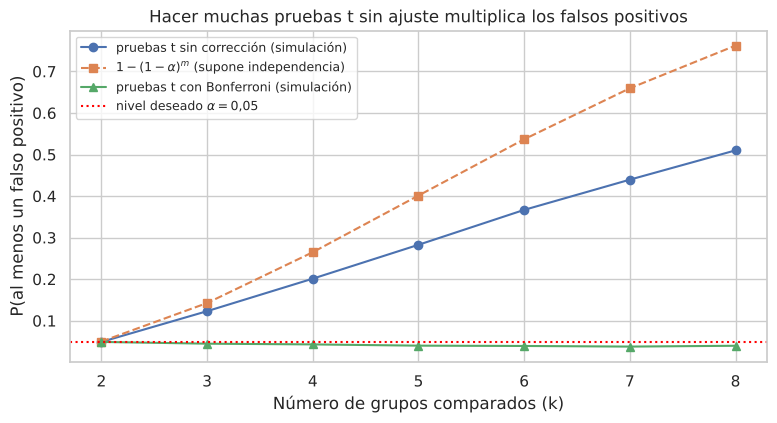

,k_grupos,pares_m,FWER sin corrección (simulada),1-(1-α)^m (supone independencia),FWER con Bonferroni α/m (simulada)
0,2,1,0.049,0.050,0.049
1,3,3,0.123,0.143,0.045
2,4,6,0.201,0.265,0.043
3,5,10,0.283,0.401,0.040
4,6,15,0.367,0.537,0.039
5,7,21,0.440,0.659,0.038
6,8,28,0.510,0.762,0.040


In [5]:
def fwer_pruebas_t(k_grupos, n_por_grupo=15, repeticiones=4000, alfa=0.05, semilla=SEMILLA):
    '''Proporción de experimentos (con H0 verdadera) con al menos un falso positivo en las pruebas t por pares.'''
    gen = np.random.default_rng(semilla)
    datos = gen.normal(50, 10, size=(repeticiones, k_grupos, n_por_grupo))   # H0 verdadera: todas las medias = 50
    pares = list(combinations(range(k_grupos), 2))
    # Prueba t vectorizada: una columna de valores p por cada par, una fila por experimento
    p_valores = np.column_stack([stats.ttest_ind(datos[:, i], datos[:, j], axis=1).pvalue for i, j in pares])
    m = len(pares)
    return {
        "k_grupos": k_grupos,
        "pares_m": m,
        "FWER sin corrección (simulada)": np.mean(p_valores.min(axis=1) < alfa),
        "1-(1-α)^m (supone independencia)": 1 - (1 - alfa) ** m,
        "FWER con Bonferroni α/m (simulada)": np.mean(p_valores.min(axis=1) < alfa / m),
    }

tabla_fwer = pd.DataFrame([fwer_pruebas_t(k) for k in range(2, 9)])

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(tabla_fwer.k_grupos, tabla_fwer["FWER sin corrección (simulada)"], "o-", label="pruebas t sin corrección (simulación)")
ax.plot(tabla_fwer.k_grupos, tabla_fwer["1-(1-α)^m (supone independencia)"], "s--", label=r"$1-(1-\alpha)^m$ (supone independencia)")
ax.plot(tabla_fwer.k_grupos, tabla_fwer["FWER con Bonferroni α/m (simulada)"], "^-", label="pruebas t con Bonferroni (simulación)")
ax.axhline(0.05, color="red", ls=":", label=r"nivel deseado $\alpha = 0{,}05$")
ax.set(xlabel="Número de grupos comparados (k)", ylabel="P(al menos un falso positivo)",
       title="Hacer muchas pruebas t sin ajuste multiplica los falsos positivos")
ax.legend(fontsize=9); plt.show()
tabla_fwer.round(3)

**Interpretación.** Con dos grupos sólo hay una prueba y la tasa de error coincide con $\alpha$. A medida que crece el número de grupos, la probabilidad de declarar al menos una diferencia inexistente se dispara: con seis grupos, aproximadamente uno de cada tres experimentos "descubre" algo falso. La simulación queda por debajo de la fórmula $1-(1-\alpha)^m$ porque las pruebas comparten grupos y están positivamente correlacionadas; la fórmula supone independencia y por eso exagera. La corrección de Bonferroni devuelve la tasa por debajo del 5 %, a costa de volver cada prueba más exigente.

Conviene distinguir lo que es **propiedad teórica** de lo que es **resultado de esta simulación**: que la FWER aumenta con $m$ y que Bonferroni la mantiene por debajo de $\alpha$ son propiedades demostrables; las cifras exactas de la tabla son estimaciones con error de Monte Carlo (con 4000 repeticiones, el error estándar de una proporción cercana a 0,3 es aproximadamente $\sqrt{0{,}3\cdot0{,}7/4000}\approx0{,}007$).

El ANOVA resuelve el problema de otra manera: plantea **una sola prueba global** de nivel $\alpha$ para la pregunta "¿hay alguna diferencia entre las medias?". Sólo si la respuesta es afirmativa se procede a localizar las diferencias con procedimientos que controlan la FWER (Unidad 5).

## 1.4 Hipótesis del ANOVA de un factor

Sea $\mu_i$ la media poblacional de la respuesta en el nivel $i$ del factor ($i=1,\dots,k$). El ANOVA de un factor contrasta

$$
H_0:\ \mu_1=\mu_2=\cdots=\mu_k
\qquad\text{frente a}\qquad
H_1:\ \mu_i\neq\mu_j \text{ para al menos un par } (i,j).
$$

Dos precisiones evitan errores frecuentes. Primero, $H_1$ **no** afirma que todas las medias sean distintas: basta con que una difiera de las demás. Segundo, rechazar $H_0$ no dice **cuáles** medias difieren ni **cuánto**; para eso se necesitan las comparaciones múltiples y los tamaños del efecto.

## 1.5 La idea central: variabilidad entre y dentro de los grupos

> **Pregunta orientadora.** Si las medias muestrales de los tres métodos son 42, 38 y 37 minutos, ¿eso basta para afirmar que los métodos difieren?

No basta, porque las medias muestrales **siempre** difieren algo, aunque sea por azar. La pregunta correcta es si difieren **más de lo que el azar produciría**. Y la magnitud del azar se estima a partir de cuánto varían las observaciones **dentro** de cada grupo. Observe los dos escenarios siguientes, construidos de modo que **las medias de los grupos son exactamente las mismas**; lo único que cambia es la dispersión interna.

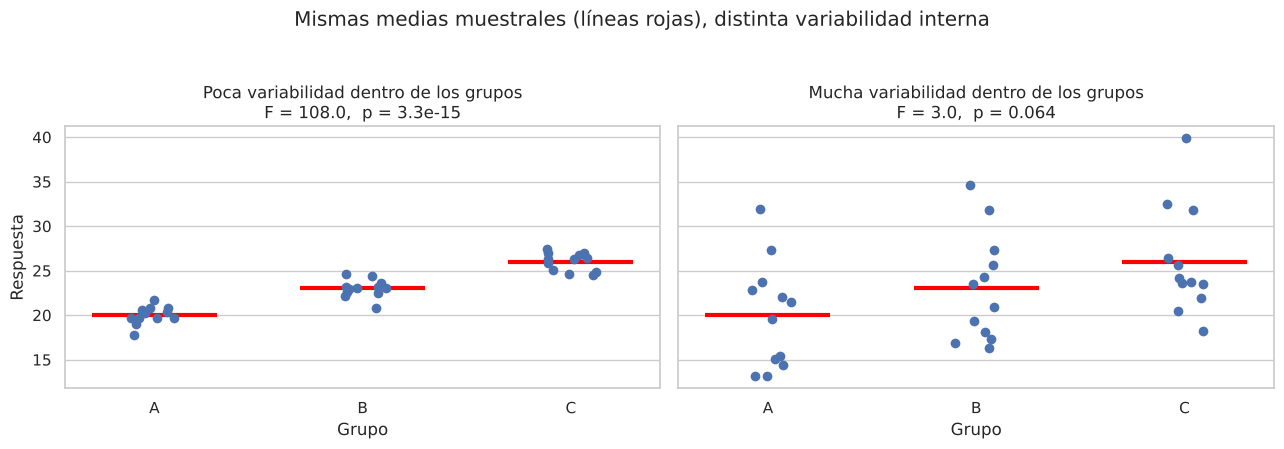

In [6]:
def grupos_con_media_y_de_exactas(medias, de, n, gen):
    '''Genera grupos cuyas media y desviación estándar muestrales coinciden EXACTAMENTE con las indicadas.'''
    filas = []
    for etiqueta, mu in zip("ABC", medias):
        z = gen.normal(0, 1, n)
        z = (z - z.mean()) / z.std(ddof=1)               # estandariza: media 0 y DE 1 exactas
        filas.append(pd.DataFrame({"grupo": etiqueta, "y": mu + de * z}))
    return pd.concat(filas, ignore_index=True)

medias_ilustracion = [20, 23, 26]
gen_ilustracion = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
for ax, de, titulo in zip(axes, [1.0, 6.0], ["Poca variabilidad dentro de los grupos", "Mucha variabilidad dentro de los grupos"]):
    datos_ilustracion = grupos_con_media_y_de_exactas(medias_ilustracion, de, 12, gen_ilustracion)
    sns.stripplot(data=datos_ilustracion, x="grupo", y="y", ax=ax, size=7, jitter=0.12)
    for posicion, mu in enumerate(medias_ilustracion):
        ax.hlines(mu, posicion - 0.3, posicion + 0.3, color="red", lw=3)
    resultado = stats.f_oneway(*[g.y for _, g in datos_ilustracion.groupby("grupo")])
    ax.set(title=f"{titulo}\nF = {resultado.statistic:.1f},  p = {resultado.pvalue:.2g}", xlabel="Grupo", ylabel="Respuesta")
fig.suptitle("Mismas medias muestrales (líneas rojas), distinta variabilidad interna", y=1.04)
plt.tight_layout(); plt.show()

**Interpretación.** En el panel izquierdo la separación entre las medias es grande **comparada** con la dispersión de cada grupo: es difícil atribuirla al azar. En el panel derecho exactamente la misma separación se confunde con el ruido. Esa comparación se resume en el estadístico

$$
F=\frac{\text{variabilidad entre los grupos}}{\text{variabilidad dentro de los grupos}},
$$

que vale aproximadamente 1 cuando $H_0$ es verdadera y tiende a crecer cuando las medias difieren. La Unidad 2 precisa cómo se mide cada una de estas variabilidades.

### Simulación 2: separación entre medias y variabilidad interna

> 🔮 **Pregunta de predicción.** Imagine que repetimos muchas veces un experimento con tres grupos de 10 observaciones. (a) Si las medias verdaderas son iguales, ¿cómo se verá el histograma de los valores de $F$? (b) Si separamos más las medias, ¿qué le pasa a ese histograma? (c) Si mantenemos la separación pero aumentamos la desviación estándar dentro de los grupos, ¿qué esperaría?

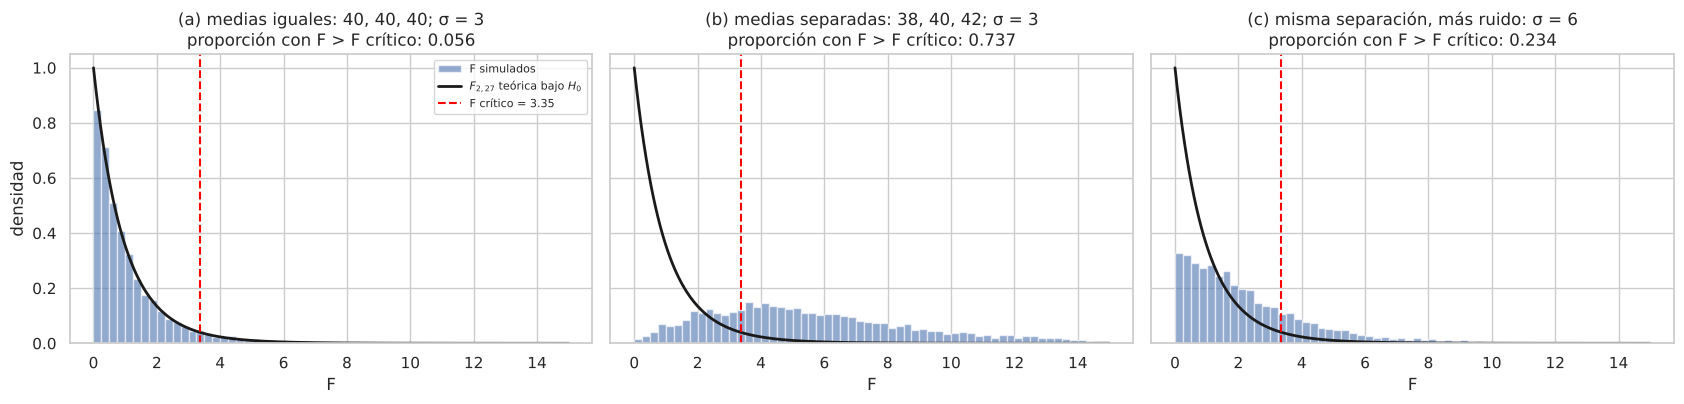

In [7]:
def simular_F(medias, sigma, n, repeticiones=5000, semilla=SEMILLA):
    '''Simula `repeticiones` experimentos de un factor y devuelve los estadísticos F (cálculo vectorizado).'''
    gen = np.random.default_rng(semilla)
    medias = np.asarray(medias, dtype=float)
    k = len(medias)
    y = gen.normal(medias[None, :, None], sigma, size=(repeticiones, k, n))
    medias_grupo = y.mean(axis=2)
    media_general = medias_grupo.mean(axis=1, keepdims=True)              # diseño balanceado
    cm_entre = n * ((medias_grupo - media_general) ** 2).sum(axis=1) / (k - 1)
    cm_dentro = ((y - medias_grupo[:, :, None]) ** 2).sum(axis=(1, 2)) / (k * (n - 1))
    return cm_entre / cm_dentro

n_sim, k_sim = 10, 3
gl1, gl2 = k_sim - 1, k_sim * (n_sim - 1)
F_critico_sim = stats.f.ppf(0.95, gl1, gl2)
escenarios_F = {
    "(a) medias iguales: 40, 40, 40; σ = 3": ([40, 40, 40], 3),
    "(b) medias separadas: 38, 40, 42; σ = 3": ([38, 40, 42], 3),
    "(c) misma separación, más ruido: σ = 6": ([38, 40, 42], 6),
}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
x_teorico = np.linspace(0, 15, 400)
for ax, (titulo, (medias_esc, sigma_esc)) in zip(axes, escenarios_F.items()):
    valores_F = simular_F(medias_esc, sigma_esc, n_sim)
    ax.hist(valores_F, bins=np.linspace(0, 15, 61), density=True, alpha=0.6, label="F simulados")
    ax.plot(x_teorico, stats.f.pdf(x_teorico, gl1, gl2), "k", lw=2, label=fr"$F_{{{gl1},{gl2}}}$ teórica bajo $H_0$")
    ax.axvline(F_critico_sim, color="red", ls="--", label=f"F crítico = {F_critico_sim:.2f}")
    ax.set(title=f"{titulo}\nproporción con F > F crítico: {np.mean(valores_F > F_critico_sim):.3f}", xlabel="F")
axes[0].set_ylabel("densidad"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretación.**

- **(a)** Cuando $H_0$ es verdadera, los valores de $F$ simulados siguen la distribución $F_{2,27}$ teórica y superan el valor crítico en cerca del 5 % de los experimentos: ese porcentaje **es** el error de tipo I. Que la distribución de referencia sea exactamente $F$ es una propiedad teórica que depende de los supuestos (normalidad, independencia, varianza común); el histograma sólo la ilustra.
- **(b)** Al separar las medias, la distribución de $F$ se desplaza a la derecha y la proporción de rechazos (la **potencia**) aumenta.
- **(c)** Con la misma separación pero el doble de desviación estándar, el denominador de $F$ crece, la distribución vuelve hacia la izquierda y la potencia cae.

La conclusión es que la capacidad de detectar diferencias depende de la **relación señal/ruido**: diferencias entre medias en relación con la variabilidad interna. Más adelante veremos que también depende del tamaño de muestra.

🤔 **Reflexión 1.2.** En una planta real, ¿qué decisiones de diseño reducen la variabilidad dentro de los grupos sin cambiar las medias de los métodos? (Piense en materias primas, operarios, turnos.)

---
# Unidad 2. Fundamento matemático del ANOVA

## 2.1 El modelo de un factor

> **Pregunta orientadora.** ¿Qué afirma exactamente un ANOVA sobre cómo se generan los datos?

Sea $y_{ij}$ la observación $j$ del grupo $i$, con $i=1,\dots,k$ y $j=1,\dots,n_i$, y sea $N=\sum_i n_i$ el total de observaciones. El **modelo de medias de celda** es

$$
y_{ij}=\mu_i+\varepsilon_{ij},\qquad \varepsilon_{ij}\overset{\text{iid}}{\sim}N(0,\sigma^2).
$$

Una forma equivalente, el **modelo de efectos**, escribe cada media como una media de referencia más un desplazamiento propio del grupo:

$$
y_{ij}=\mu+\tau_i+\varepsilon_{ij},\qquad \tau_i=\mu_i-\mu .
$$

Con esta notación, $H_0:\mu_1=\cdots=\mu_k$ es lo mismo que $H_0:\tau_1=\cdots=\tau_k=0$.

La línea $\varepsilon_{ij}\overset{\text{iid}}{\sim}N(0,\sigma^2)$ contiene los supuestos del modelo, que son la "estructura paramétrica rígida" mencionada en la competencia:

| Supuesto | Qué afirma | Consecuencia si falla |
|---|---|---|
| **Independencia** | Los errores no están relacionados entre sí | Es el más grave: los errores estándar y los valores $p$ dejan de ser válidos |
| **Media cero** | Los grupos difieren *sólo* en $\mu_i$ | Si hay otra fuente sistemática (una covariable, un bloque), se confunde con el efecto del factor |
| **Homocedasticidad** | La **misma** varianza $\sigma^2$ en todos los grupos | La prueba $F$ puede volverse liberal o conservadora, sobre todo con grupos de tamaños distintos |
| **Normalidad** | Los errores son normales | Con muestras moderadas y diseño balanceado la prueba $F$ es bastante robusta |

Observe que el modelo dice que **todo** lo que distingue a un grupo de otro es un desplazamiento de la media: la forma de la distribución y su dispersión son idénticas. Si en la realidad un grupo es mucho más disperso, el modelo no tiene un parámetro para representarlo. Las implicaciones técnicas de la parametrización (por qué $\mu$ y los $\tau_i$ no se pueden estimar sin una restricción adicional) se desarrollan en la Unidad 7.

## 2.2 Medias y descomposición de la variabilidad

Definimos la media de cada grupo y la media general:

$$
\bar y_{i\cdot}=\frac{1}{n_i}\sum_{j=1}^{n_i}y_{ij},\qquad
\bar y_{\cdot\cdot}=\frac{1}{N}\sum_{i=1}^{k}\sum_{j=1}^{n_i}y_{ij}.
$$

Cada desviación respecto a la media general se puede partir en dos piezas:

$$
\underbrace{(y_{ij}-\bar y_{\cdot\cdot})}_{\text{desviación total}}
=\underbrace{(\bar y_{i\cdot}-\bar y_{\cdot\cdot})}_{\text{entre grupos}}
+\underbrace{(y_{ij}-\bar y_{i\cdot})}_{\text{dentro del grupo}} .
$$

Al elevar al cuadrado y sumar sobre todas las observaciones, el término cruzado se anula, porque dentro de cada grupo $\sum_j(y_{ij}-\bar y_{i\cdot})=0$. Se obtiene la **identidad fundamental del ANOVA**:

$$
\underbrace{\sum_{i}\sum_{j}(y_{ij}-\bar y_{\cdot\cdot})^2}_{SC_T}
=\underbrace{\sum_{i}n_i(\bar y_{i\cdot}-\bar y_{\cdot\cdot})^2}_{SC_{Tr}}
+\underbrace{\sum_{i}\sum_{j}(y_{ij}-\bar y_{i\cdot})^2}_{SC_E}.
$$

$SC_T$ es la suma de cuadrados **total**, $SC_{Tr}$ la suma de cuadrados **entre tratamientos** y $SC_E$ la suma de cuadrados **del error** o **dentro** de los grupos.

## 2.3 Grados de libertad, cuadrados medios y estadístico $F$

Cada suma de cuadrados tiene asociados unos grados de libertad, que también se descomponen: $N-1=(k-1)+(N-k)$. Al dividir cada suma de cuadrados por sus grados de libertad se obtienen los **cuadrados medios**:

$$
CM_{Tr}=\frac{SC_{Tr}}{k-1},\qquad CM_E=\frac{SC_E}{N-k},\qquad F=\frac{CM_{Tr}}{CM_E}.
$$

¿Por qué tiene sentido este cociente? Porque sus valores esperados son

$$
E(CM_E)=\sigma^2,\qquad E(CM_{Tr})=\sigma^2+\frac{\sum_{i}n_i\tau_i^2}{k-1}.
$$

$CM_E$ estima la varianza del error tanto si $H_0$ es cierta como si no. $CM_{Tr}$ también estima $\sigma^2$ cuando todos los $\tau_i$ son cero, pero se infla cuando hay diferencias entre medias. Bajo $H_0$ y los supuestos del modelo, $F$ sigue una distribución $F$ de Snedecor con $k-1$ y $N-k$ grados de libertad:

$$
F\;\sim\;F_{k-1,\;N-k}\quad\text{si }H_0\text{ es verdadera}.
$$

Se rechaza $H_0$ cuando $F$ es grande: si $F>F_{1-\alpha;\,k-1,\,N-k}$, o equivalentemente si el valor $p=P(F_{k-1,N-k}\ge F_{\text{obs}})$ es menor que $\alpha$.

## 2.4 La tabla ANOVA

| Fuente de variación | Suma de cuadrados | Grados de libertad | Cuadrado medio | $F$ | Valor $p$ |
|---|---|---|---|---|---|
| Entre grupos (tratamientos) | $SC_{Tr}$ | $k-1$ | $CM_{Tr}$ | $CM_{Tr}/CM_E$ | $P(F_{k-1,N-k}\ge F)$ |
| Dentro de los grupos (error) | $SC_E$ | $N-k$ | $CM_E$ | | |
| Total | $SC_T$ | $N-1$ | | | |

## 2.5 Ejemplo numérico resuelto a mano

> **Pregunta orientadora.** Antes de usar el computador, ¿podemos reproducir con lápiz cada número de una tabla ANOVA?

Un supervisor registra el tiempo (en minutos) que tardan **cuatro** órdenes pequeñas con cada uno de tres métodos:

| Método | Observaciones | Suma | Media $\bar y_{i\cdot}$ |
|---|---|---|---|
| A | 8, 10, 9, 13 | 40 | 10 |
| B | 11, 14, 13, 14 | 52 | 13 |
| C | 6, 8, 5, 9 | 28 | 7 |

Hay $k=3$ grupos, $n_i=4$ y $N=12$. La media general es $\bar y_{\cdot\cdot}=(40+52+28)/12=120/12=10$.

**Paso 1. Suma de cuadrados entre grupos.**

$$
SC_{Tr}=4(10-10)^2+4(13-10)^2+4(7-10)^2=0+36+36=72 .
$$

**Paso 2. Suma de cuadrados dentro de los grupos.** Se restan las medias de cada grupo:

| Método | Desviaciones $y_{ij}-\bar y_{i\cdot}$ | Cuadrados | Suma |
|---|---|---|---|
| A | $-2,\ 0,\ -1,\ 3$ | $4,\ 0,\ 1,\ 9$ | 14 |
| B | $-2,\ 1,\ 0,\ 1$ | $4,\ 1,\ 0,\ 1$ | 6 |
| C | $-1,\ 1,\ -2,\ 2$ | $1,\ 1,\ 4,\ 4$ | 10 |

$SC_E=14+6+10=30$.

**Paso 3. Suma de cuadrados total** (como comprobación): las desviaciones respecto a 10 son $-2,0,-1,3;\ 1,4,3,4;\ -4,-2,-5,-1$, cuyos cuadrados suman $14+42+46=102=72+30$. ✔

**Paso 4. Grados de libertad y cuadrados medios.** $k-1=2$, $N-k=9$, $N-1=11$. Entonces $CM_{Tr}=72/2=36$ y $CM_E=30/9\approx3{,}33$.

**Paso 5. Estadístico y decisión.** $F=36/3{,}33=10{,}8$. En la tabla de la distribución $F$, el valor crítico con $\alpha=0{,}05$ es $F_{0{,}95;\,2,\,9}\approx4{,}26$. Como $10{,}8>4{,}26$, se rechaza $H_0$.

| Fuente | SC | gl | CM | $F$ |
|---|---|---|---|---|
| Método | 72 | 2 | 36,00 | 10,8 |
| Error | 30 | 9 | 3,33 | |
| Total | 102 | 11 | | |

Ahora verificamos cada número con Python.

In [8]:
ejemplo_mano = pd.DataFrame({
    "metodo": ["A"] * 4 + ["B"] * 4 + ["C"] * 4,
    "tiempo": [8, 10, 9, 13, 11, 14, 13, 14, 6, 8, 5, 9],
})

media_general_mano = ejemplo_mano.tiempo.mean()
resumen_mano = ejemplo_mano.groupby("metodo").tiempo.agg(n="count", media="mean")
sc_entre_mano = (resumen_mano.n * (resumen_mano.media - media_general_mano) ** 2).sum()
sc_dentro_mano = ((ejemplo_mano.tiempo - ejemplo_mano.metodo.map(resumen_mano.media)) ** 2).sum()
sc_total_mano = ((ejemplo_mano.tiempo - media_general_mano) ** 2).sum()

k_mano, N_mano = ejemplo_mano.metodo.nunique(), len(ejemplo_mano)
F_mano = (sc_entre_mano / (k_mano - 1)) / (sc_dentro_mano / (N_mano - k_mano))
print(f"Media general = {media_general_mano}")
print(f"SC_Tr = {sc_entre_mano:.0f}   SC_E = {sc_dentro_mano:.0f}   SC_T = {sc_total_mano:.0f}")
print(f"F = {F_mano:.2f}   F crítico (0,95; 2; 9) = {stats.f.ppf(0.95, 2, 9):.3f}   "
      f"valor p = {stats.f.sf(F_mano, 2, 9):.4f}")

Media general = 10.0
SC_Tr = 72   SC_E = 30   SC_T = 102
F = 10.80   F crítico (0,95; 2; 9) = 4.256   valor p = 0.0041


In [9]:
# La misma tabla con statsmodels: el ANOVA es un modelo lineal con un predictor categórico
modelo_mano = smf.ols("tiempo ~ C(metodo)", data=ejemplo_mano).fit()
sm.stats.anova_lm(modelo_mano)

,df,sum_sq,mean_sq,F,PR(>F)
C(metodo),2.0,72.0,36.0000,10.8,0.0041
Residual,9.0,30.0,3.3333,NaN,NaN


**Interpretación.** Los cálculos coinciden. El valor $p\approx0{,}004$ significa que, **si los tres métodos tuvieran la misma media poblacional y se cumplieran los supuestos del modelo**, la probabilidad de obtener un $F$ igual o mayor que 10,8 sería de 0,4 %. Es una probabilidad sobre los **datos** bajo $H_0$; **no** es la probabilidad de que $H_0$ sea verdadera, ni la probabilidad de haberse equivocado.

## 2.6 La distribución $F$ y la región de rechazo

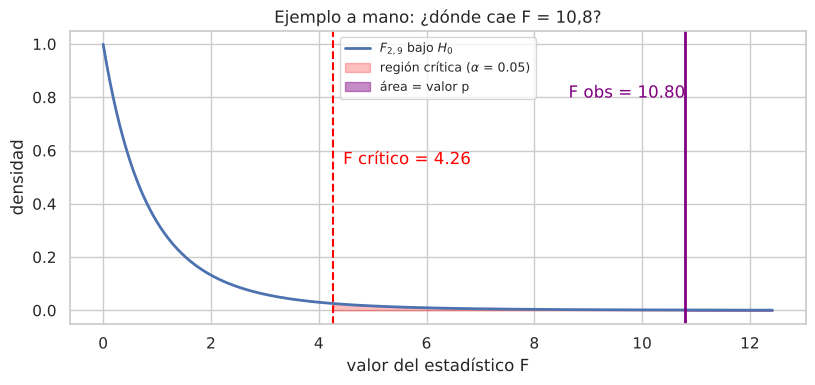

In [10]:
def graficar_distribucion_F(F_observado, gl_num, gl_den, alfa=0.05, titulo=""):
    '''Dibuja la distribución F bajo H0, la región crítica y el valor p del estadístico observado.'''
    F_crit = stats.f.ppf(1 - alfa, gl_num, gl_den)
    x_max = max(F_crit * 2.5, min(F_observado * 1.15, 25))
    x = np.linspace(0.001, x_max, 600)
    densidad = stats.f.pdf(x, gl_num, gl_den)
    fig, ax = plt.subplots(figsize=(9.5, 3.8))
    ax.plot(x, densidad, lw=2, label=fr"$F_{{{gl_num},{gl_den}}}$ bajo $H_0$")
    ax.fill_between(x, densidad, where=x >= F_crit, color="red", alpha=0.25, label=fr"región crítica ($\alpha$ = {alfa})")
    ax.fill_between(x, densidad, where=x >= F_observado, color="purple", alpha=0.45, label="área = valor p")
    ax.axvline(F_crit, color="red", ls="--")
    ax.text(F_crit, densidad.max() * 0.55, f"  F crítico = {F_crit:.2f}", color="red")
    ax.axvline(min(F_observado, x_max), color="purple", lw=2)
    texto = f"F obs = {F_observado:.2f}" + ("  (fuera del gráfico →)" if F_observado > x_max else "")
    ax.text(min(F_observado, x_max), densidad.max() * 0.8, texto, color="purple", ha="right" if F_observado > x_max * 0.7 else "left")
    ax.set(xlabel="valor del estadístico F", ylabel="densidad", title=titulo); ax.legend(fontsize=9)
    plt.show()
    return F_crit, stats.f.sf(F_observado, gl_num, gl_den)

F_crit_mano, p_mano = graficar_distribucion_F(F_mano, 2, 9, titulo="Ejemplo a mano: ¿dónde cae F = 10,8?")

**Interpretación.** El área morada (a la derecha del $F$ observado) es el valor $p$; el área roja (a la derecha del valor crítico) es $\alpha$. Como el $F$ observado cae dentro de la región crítica, el área morada es menor que la roja y se rechaza $H_0$.

🤔 **Reflexión 2.1.** Cambie mentalmente la observación 13 del método A por 19. ¿Qué sumas de cuadrados cambian? ¿Aumentará o disminuirá $F$? Compruébelo modificando la celda del ejemplo.

---
# Unidad 3. ANOVA de un factor con Python

El procedimiento completo tiene siempre la misma secuencia: **formular** el problema, **explorar** los datos, **ajustar** el modelo, **diagnosticar** los supuestos, **localizar** las diferencias, **cuantificar** su magnitud y **redactar** la conclusión con el alcance que permite el diseño. Esta unidad cubre la exploración, el ajuste y la redacción; las Unidades 4 y 5 completan el diagnóstico, las comparaciones y los tamaños del efecto.

## 3.1 Caso A (experimento simulado): métodos de producción

### Exploración descriptiva

In [11]:
descriptivos_produccion = produccion.groupby("metodo", observed=True).tiempo_min.agg(
    n="count", media="mean", desviacion_estandar="std", minimo="min", mediana="median", maximo="max")
descriptivos_produccion.round(2)

,n,media,desviacion_estandar,minimo,mediana,maximo
metodo,,,,,,
A_actual,10,41.63,2.63,36.3,41.25,46.2
B_semiautomatico,10,37.78,1.86,33.9,37.75,40.2
C_celda_U,10,37.56,2.82,33.3,37.05,42.5


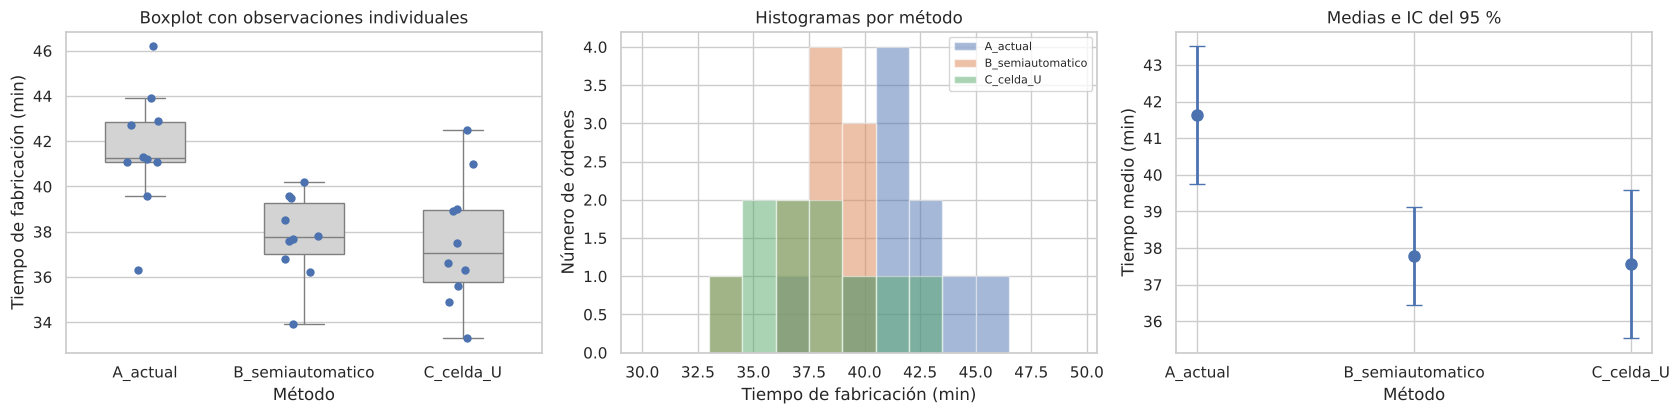

In [12]:
def grafico_medias_ic(datos, factor, respuesta, ax, nivel=0.95, etiqueta_y=""):
    '''Medias por grupo con intervalos de confianza t individuales (cada grupo usa su propia desviación estándar).'''
    resumen = datos.groupby(factor, observed=True)[respuesta].agg(["mean", "std", "count"])
    t_crit = stats.t.ppf(0.5 + nivel / 2, resumen["count"] - 1)
    semiancho = t_crit * resumen["std"] / np.sqrt(resumen["count"])
    posiciones = np.arange(len(resumen))
    ax.errorbar(posiciones, resumen["mean"], yerr=semiancho, fmt="o", capsize=6, ms=8, lw=2)
    ax.set_xticks(posiciones, resumen.index, rotation=0)
    ax.set(ylabel=etiqueta_y, title=f"Medias e IC del {int(nivel*100)} %")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
sns.boxplot(data=produccion, x="metodo", y="tiempo_min", ax=axes[0], color="lightgray", width=0.5, showfliers=False)
sns.stripplot(data=produccion, x="metodo", y="tiempo_min", ax=axes[0], size=6, jitter=0.12)
axes[0].set(title="Boxplot con observaciones individuales", xlabel="Método", ylabel="Tiempo de fabricación (min)")
for metodo, grupo in produccion.groupby("metodo", observed=True):
    axes[1].hist(grupo.tiempo_min, bins=np.arange(30, 50, 1.5), alpha=0.5, label=metodo)
axes[1].set(title="Histogramas por método", xlabel="Tiempo de fabricación (min)", ylabel="Número de órdenes")
axes[1].legend(fontsize=8)
grafico_medias_ic(produccion, "metodo", "tiempo_min", axes[2], etiqueta_y="Tiempo medio (min)")
axes[2].set_xlabel("Método")
plt.tight_layout(); plt.show()

**Interpretación.** El método actual (A) muestra tiempos visiblemente mayores que B y C, que se parecen entre sí. Las dispersiones son similares (desviaciones estándar entre 1,9 y 2,8 minutos), los grupos tienen el mismo tamaño y no se ven valores extremos. Con 10 observaciones por grupo los histogramas son poco informativos sobre la forma de la distribución: ese es un límite general de la exploración con muestras pequeñas. Los intervalos de confianza de la derecha son **individuales** (uno por grupo); que dos intervalos se traslapen **no** equivale a que la diferencia no sea significativa, y por eso no se usan para decidir: para eso está la prueba formal.

### Ajuste del modelo y tabla ANOVA

En `statsmodels` el ANOVA se ajusta como un modelo lineal con la fórmula `respuesta ~ C(factor)`; la función `anova_lm` produce la tabla.

In [13]:
modelo_produccion = smf.ols("tiempo_min ~ C(metodo)", data=produccion).fit()
tabla_produccion = sm.stats.anova_lm(modelo_produccion)
tabla_produccion

,df,sum_sq,mean_sq,F,PR(>F)
C(metodo),2.0,104.786,52.3930,8.5702,0.0013
Residual,27.0,165.061,6.1134,NaN,NaN


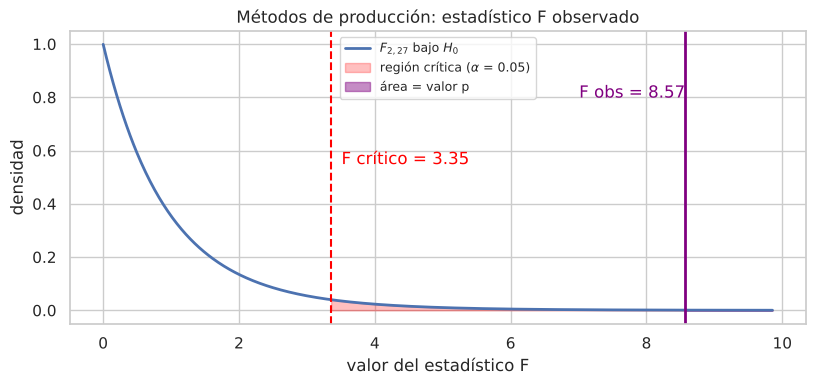

In [14]:
F_produccion = tabla_produccion.loc["C(metodo)", "F"]
gl_produccion = (int(tabla_produccion.loc["C(metodo)", "df"]), int(tabla_produccion.loc["Residual", "df"]))
_ = graficar_distribucion_F(F_produccion, *gl_produccion, titulo="Métodos de producción: estadístico F observado")

**Interpretación de la tabla.**

- La fila `C(metodo)` contiene la variabilidad **entre** métodos ($k-1=2$ grados de libertad); `Residual` contiene la variabilidad **dentro** de los métodos ($N-k=27$ grados de libertad).
- El cuadrado medio entre métodos es varias veces mayor que el cuadrado medio del error, de ahí que $F\approx8{,}6$.
- El valor $p\approx0{,}001$ indica que un $F$ tan grande sería muy poco frecuente si los tres métodos tuvieran el mismo tiempo medio.

### Redacción de la conclusión

Una conclusión estadística completa reporta el estadístico, los grados de libertad, el valor $p$, un tamaño del efecto y el **alcance** que permite el diseño. Por ejemplo:

> *Se encontró evidencia de que el tiempo medio de fabricación difiere según el método de producción, $F(2,\,27)=8{,}57$, $p=0{,}001$, $\eta^2=0{,}39$. Como los métodos se asignaron aleatoriamente a las órdenes de producción, la diferencia puede atribuirse al método, dentro de las condiciones del experimento (referencia de pieza, tamaño de lote y período estudiados). Las comparaciones por pares (Unidad 5) indican cuáles métodos difieren.*

El tamaño del efecto $\eta^2$ se define en la Unidad 5; aquí sólo anticipamos que el método explica alrededor del 39 % de la variabilidad del tiempo.

## 3.2 Caso B (datos reales, observacionales): precio de automóviles según su tipo

> **Pregunta orientadora.** ¿El precio de venta de un automóvil nuevo se asocia con su tipo de carrocería?

**Contexto de los datos.** `Cars93` contiene información de 93 modelos de automóviles de pasajeros a la venta en EE. UU. en 1993, recopilada a partir de *Consumer Reports* y del *PACE New Car & Truck 1993 Buying Guide* (Lock, 1993). La variable `Price` es el precio medio de la versión básica y la versión equipada, en **miles de dólares de 1993**; `Type` clasifica el vehículo en seis categorías: *Small, Compact, Midsize, Large, Sporty* y *Van*.

**Unidad de observación y alcance.** Cada fila es un **modelo** de automóvil, no un vehículo vendido. El tipo no se asignó al azar: los fabricantes deciden tipo, motor, equipamiento y precio simultáneamente. Por tanto cualquier diferencia que encontremos será una **asociación**; no podremos afirmar que el tipo *causa* el precio. Tampoco es una muestra aleatoria de una población bien definida: es una selección de modelos de un año concreto, y la generalización a otros mercados o años no está garantizada.

In [15]:
cars = pd.read_csv(ruta_datos("Cars93.csv"), index_col=0)
cars.columns = [c.replace(".", "_") for c in cars.columns]          # nombres compatibles con fórmulas
ORDEN_TIPOS = ["Small", "Compact", "Midsize", "Large", "Sporty", "Van"]
cars["Type"] = pd.Categorical(cars["Type"], categories=ORDEN_TIPOS)
print(f"{cars.shape[0]} modelos y {cars.shape[1]} variables; faltantes en Price/Type: {cars[['Price', 'Type']].isna().sum().sum()}")
cars[["Manufacturer", "Model", "Type", "Origin", "DriveTrain", "Horsepower", "Price"]].head(6)

93 modelos y 27 variables; faltantes en Price/Type: 0


,Manufacturer,Model,Type,Origin,DriveTrain,Horsepower,Price
1,Acura,Integra,Small,non-USA,Front,140,15.9
2,Acura,Legend,Midsize,non-USA,Front,200,33.9
3,Audi,90,Compact,non-USA,Front,172,29.1
4,Audi,100,Midsize,non-USA,Front,172,37.7
5,BMW,535i,Midsize,non-USA,Rear,208,30.0
6,Buick,Century,Midsize,USA,Front,110,15.7


In [16]:
descriptivos_cars = cars.groupby("Type", observed=True).Price.agg(
    n="count", media="mean", desviacion_estandar="std", mediana="median", minimo="min", maximo="max")
descriptivos_cars["coef_variacion_%"] = 100 * descriptivos_cars.desviacion_estandar / descriptivos_cars.media
descriptivos_cars.round(2)

,n,media,desviacion_estandar,mediana,minimo,maximo,coef_variacion_%
Type,,,,,,,
Small,21,10.17,1.95,10.00,7.4,15.9,19.21
Compact,16,18.21,6.69,16.15,11.1,31.9,36.72
Midsize,22,27.22,12.26,26.20,13.9,61.9,45.06
Large,11,24.30,6.34,20.90,18.4,36.1,26.08
Sporty,14,19.39,7.97,16.80,10.0,38.0,41.12
Van,9,19.10,1.88,19.10,16.3,22.7,9.83


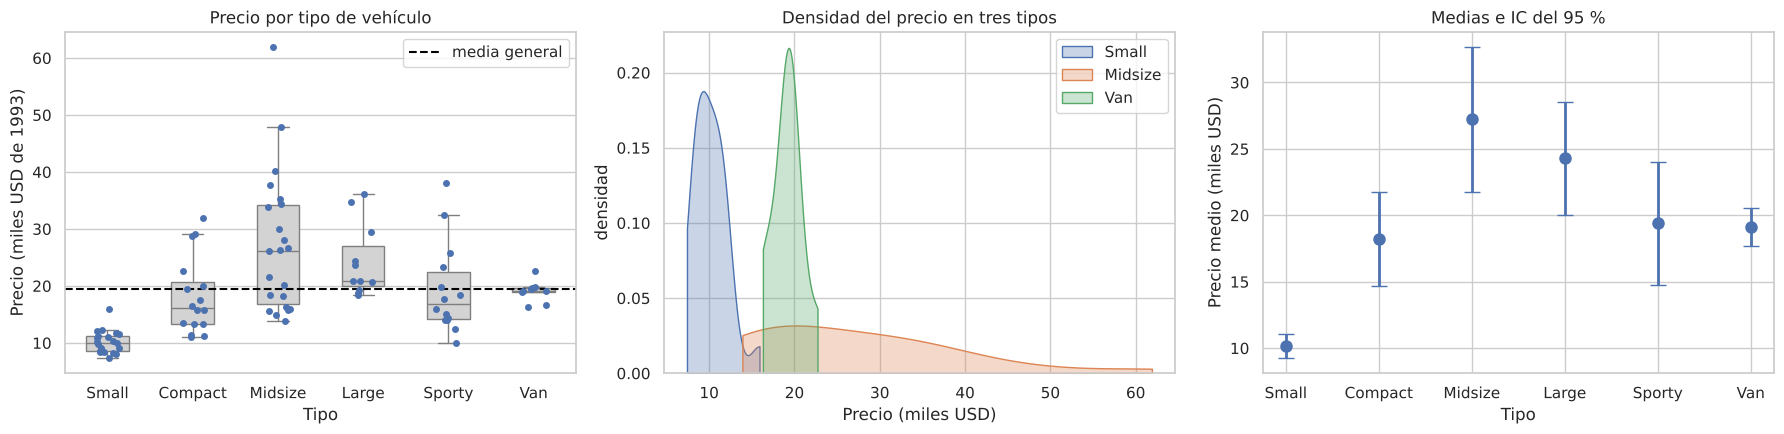

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=cars, x="Type", y="Price", ax=axes[0], color="lightgray", width=0.5, showfliers=False)
sns.stripplot(data=cars, x="Type", y="Price", ax=axes[0], size=5, jitter=0.15)
axes[0].axhline(cars.Price.mean(), ls="--", color="black", label="media general")
axes[0].set(title="Precio por tipo de vehículo", xlabel="Tipo", ylabel="Precio (miles USD de 1993)"); axes[0].legend()
for tipo in ["Small", "Midsize", "Van"]:
    sns.kdeplot(cars.loc[cars.Type == tipo, "Price"], ax=axes[1], fill=True, alpha=0.3, label=tipo, cut=0)
axes[1].set(title="Densidad del precio en tres tipos", xlabel="Precio (miles USD)", ylabel="densidad"); axes[1].legend()
grafico_medias_ic(cars, "Type", "Price", axes[2], etiqueta_y="Precio medio (miles USD)")
axes[2].set_xlabel("Tipo")
plt.tight_layout(); plt.show()

**Interpretación.** Los automóviles pequeños son claramente más baratos y los medianos los más caros en promedio. Pero hay algo más importante para el análisis: **la dispersión es muy distinta entre grupos**. Los pequeños y las *vans* tienen desviaciones estándar cercanas a 2 mil dólares, mientras que los medianos superan los 12 mil, con varios modelos de lujo en la cola derecha. El diseño además está **desbalanceado** (entre 9 y 22 modelos por tipo). Esa combinación, varianzas distintas y tamaños distintos, es justamente la situación en la que la prueba $F$ clásica es menos confiable (lo comprobaremos en la Unidad 4).

Ajustamos de todos modos el ANOVA clásico, porque así se haría sin diagnóstico, y dejamos la conclusión como **provisional**.

In [18]:
modelo_cars_precio = smf.ols("Price ~ C(Type)", data=cars).fit()
sm.stats.anova_lm(modelo_cars_precio)

,df,sum_sq,mean_sq,F,PR(>F)
C(Type),5.0,3421.4351,684.2870,11.5316,1.4770e-08
Residual,87.0,5162.5862,59.3401,NaN,NaN


**Conclusión provisional.** El estadístico $F(5,\,87)\approx11{,}5$ con $p<0{,}001$ sugiere que el precio medio no es igual en todos los tipos. Sin embargo, la validez de ese valor $p$ descansa en supuestos que la exploración ya pone en duda. La Unidad 4 evalúa si podemos confiar en él.

🤔 **Reflexión 3.1.** Redacte, para el caso `Cars93`, una conclusión que respete el carácter observacional de los datos. ¿Qué palabras del ejemplo de producción **no** debería usar?

---
# Unidad 4. Validación y diagnóstico del modelo

> **Pregunta orientadora.** El valor $p$ de la prueba $F$ es una promesa: "si $H_0$ es verdadera, me equivoco el 5 % de las veces". ¿Bajo qué condiciones se cumple esa promesa y cómo verificamos que se cumplen?

Los supuestos se refieren a los **errores** $\varepsilon_{ij}$, que no se observan. Los estimamos con los **residuos** $e_{ij}=y_{ij}-\bar y_{i\cdot}$, es decir, la diferencia entre cada observación y la media de su grupo. Por eso el supuesto correcto no es que "la variable respuesta sea normal", sino que la respuesta sea normal **dentro de cada grupo** (normalidad condicional), lo que equivale a que los residuos sean normales. Una respuesta cuyo histograma global es bimodal puede cumplir perfectamente el supuesto si cada grupo es normal.

La estrategia recomendada combina tres fuentes de evidencia: el **diseño** (que justifica la independencia), los **gráficos** de residuos (que muestran la forma y la magnitud de las desviaciones) y las **pruebas formales** (que dan una medida de incertidumbre, pero tienen limitaciones importantes que discutiremos).

## 4.1 Independencia

La independencia no se verifica con una prueba aplicada a la tabla de datos: se **garantiza con el diseño**. Las preguntas que hay que hacerse son: ¿se asignaron los tratamientos al azar? ¿cada unidad experimental se midió una sola vez? ¿hay agrupamientos (operario, máquina, día) que hagan que unas observaciones se parezcan más entre sí? ¿hay un orden temporal?

Cuando existe un orden de ejecución, un gráfico de residuos frente al orden permite detectar tendencias (desgaste de una herramienta, aprendizaje del operario) que violarían la independencia.

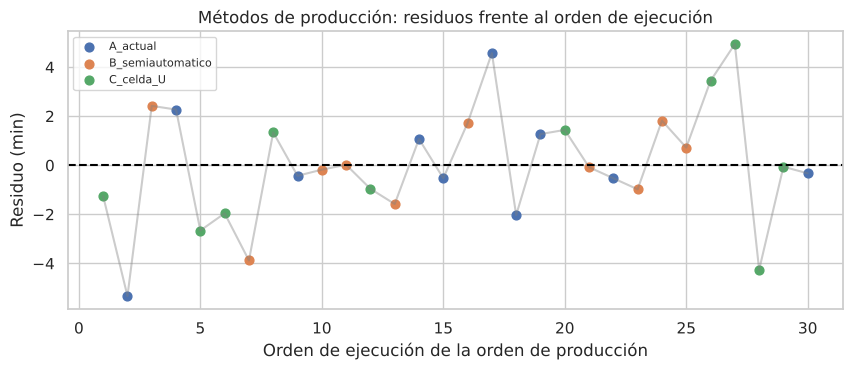

Durbin-Watson (residuos ordenados en el tiempo) = 2.05


In [19]:
produccion["residuo"] = modelo_produccion.resid
datos_orden = produccion.sort_values("orden_ejecucion")
fig, ax = plt.subplots(figsize=(10, 3.6))
for metodo, grupo in datos_orden.groupby("metodo", observed=True):
    ax.scatter(grupo.orden_ejecucion, grupo.residuo, label=metodo, s=40)
ax.plot(datos_orden.orden_ejecucion, datos_orden.residuo, color="gray", alpha=0.4)
ax.axhline(0, ls="--", color="black")
ax.set(xlabel="Orden de ejecución de la orden de producción", ylabel="Residuo (min)",
       title="Métodos de producción: residuos frente al orden de ejecución")
ax.legend(fontsize=8); plt.show()

# Estadístico de Durbin-Watson: cercano a 2 indica ausencia de autocorrelación de primer orden
from statsmodels.stats.stattools import durbin_watson
print(f"Durbin-Watson (residuos ordenados en el tiempo) = {durbin_watson(datos_orden.residuo):.2f}")

**Interpretación.** Los residuos oscilan alrededor de cero sin tendencias ni rachas largas, y el estadístico de Durbin-Watson está cerca de 2. Junto con la asignación aleatoria, esto respalda la independencia. En `Cars93` no hay orden temporal: cada modelo es una unidad distinta, pero conviene notar que varios modelos provienen del mismo fabricante y podrían compartir políticas de precios; esa posible dependencia no la podemos descartar con estos datos y es una limitación que debe declararse.

## 4.2 Normalidad condicional de los errores

**Herramienta gráfica: el gráfico Q-Q.** Ordena los residuos y los compara con los cuantiles que tendría una distribución normal. Si los puntos siguen la diagonal, la normalidad es razonable; curvaturas sistemáticas indican asimetría, y desviaciones en los extremos indican colas más pesadas o más livianas.

**Prueba formal: Shapiro-Wilk.** Contrasta $H_0$: *los residuos provienen de una distribución normal*. Tres advertencias son indispensables:

1. Un valor $p>0{,}05$ **no demuestra** normalidad; sólo indica que los datos no aportan evidencia suficiente en su contra. Con muestras pequeñas la prueba tiene poca potencia y casi nunca rechaza.
2. Con muestras grandes la prueba rechaza desviaciones minúsculas que no afectan en nada al ANOVA.
3. La prueba $F$ es bastante robusta a la no normalidad cuando los grupos tienen tamaños similares y moderados, gracias al teorema central del límite aplicado a las medias. Lo que importa es la **magnitud** de la desviación, que se juzga mejor en el gráfico.

## 4.3 Homogeneidad de varianzas (homocedasticidad)

**Herramienta gráfica:** residuos frente a valores ajustados (en un ANOVA de un factor, los valores ajustados son las medias de los grupos, así que cada grupo aparece como una columna vertical de puntos). Si las columnas tienen anchos muy distintos, la varianza no es homogénea. Un patrón en forma de embudo, con más dispersión en los grupos de media alta, sugiere una transformación logarítmica.

**Pruebas formales**, todas con $H_0$: *las varianzas poblacionales de los grupos son iguales*:

| Prueba | Idea | Comentario |
|---|---|---|
| **Levene (centrada en la mediana)**, también llamada Brown-Forsythe | ANOVA sobre las desviaciones absolutas respecto a la mediana de cada grupo | Robusta a la no normalidad; recomendada por defecto |
| **Bartlett** | Basada en el cociente de varianzas bajo normalidad | Más potente si los datos son normales, pero muy sensible a la no normalidad: puede rechazar por colas pesadas y no por varianzas distintas |
| **Fligner-Killeen** | Basada en rangos | No paramétrica; robusta frente a atípicos |

Una regla práctica complementaria, citada con frecuencia en la literatura aplicada, es comparar la mayor y la menor desviación estándar de los grupos: si el cociente supera aproximadamente 2 a 3, especialmente con grupos de tamaños distintos, conviene usar métodos que no supongan varianza común. Es una orientación, no un umbral exacto.

## 4.4 Valores atípicos e influencia

Un **residuo estudentizado** es el residuo dividido por una estimación de su desviación estándar; valores con magnitud superior a 3 merecen revisión. La **distancia de Cook** mide cuánto cambiarían las estimaciones si se eliminara una observación. Un atípico no se elimina porque "estorba": se investiga (¿error de digitación? ¿unidad de otra población?) y, si se conserva, se evalúa la **sensibilidad** de las conclusiones a su presencia.

## 4.5 Diagnóstico aplicado

Reunimos los gráficos y las pruebas en una función que aplicaremos a los dos casos.

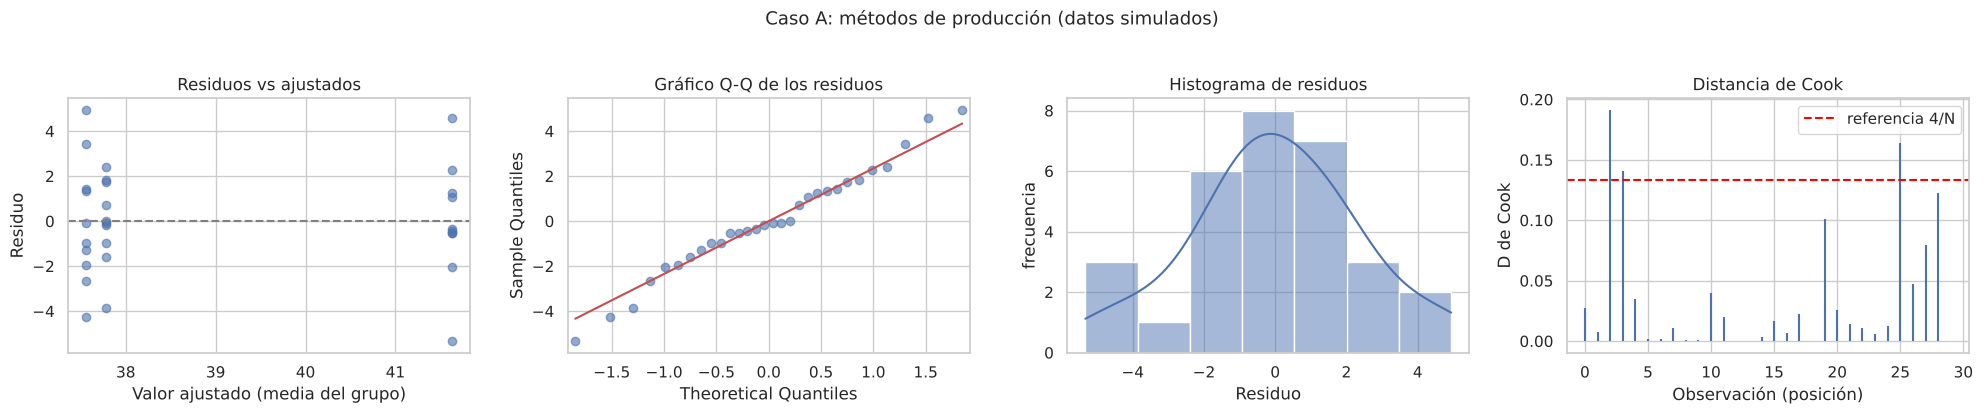

,prueba,estadistico,valor_p
0,Shapiro-Wilk (normalidad de residuos),0.9836,0.9100
1,Levene-mediana (igualdad de varianzas),0.7411,0.4860
2,"Bartlett (igualdad de varianzas, exige normali...",1.5481,0.4611
3,Fligner-Killeen (igualdad de varianzas),1.8336,0.3998


Cociente DE máxima / DE mínima entre grupos: 1.5
Residuos estudentizados con |r| > 3: 0


In [20]:
def diagnostico_anova(datos, respuesta, factor, titulo):
    '''Ajusta el ANOVA de un factor y presenta el diagnóstico gráfico y formal de sus residuos.'''
    modelo = smf.ols(f"{respuesta} ~ C({factor})", data=datos).fit()
    influencia = modelo.get_influence()
    res_estudentizados = influencia.resid_studentized_external
    distancia_cook = influencia.cooks_distance[0]
    residuos_por_grupo = [r.values for _, r in modelo.resid.groupby(datos[factor], observed=True)]

    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    axes[0].scatter(modelo.fittedvalues, modelo.resid, alpha=0.6)
    axes[0].axhline(0, ls="--", color="gray")
    axes[0].set(xlabel="Valor ajustado (media del grupo)", ylabel="Residuo", title="Residuos vs ajustados")
    sm.qqplot(modelo.resid, line="s", ax=axes[1], alpha=0.6)
    axes[1].set_title("Gráfico Q-Q de los residuos")
    sns.histplot(modelo.resid, kde=True, ax=axes[2])
    axes[2].set(title="Histograma de residuos", xlabel="Residuo", ylabel="frecuencia")
    axes[3].stem(np.arange(len(distancia_cook)), distancia_cook, markerfmt=" ", basefmt=" ")
    axes[3].axhline(4 / len(distancia_cook), ls="--", color="red", label="referencia 4/N")
    axes[3].set(title="Distancia de Cook", xlabel="Observación (posición)", ylabel="D de Cook"); axes[3].legend()
    fig.suptitle(titulo, y=1.03, fontsize=13); plt.tight_layout(); plt.show()

    de_grupos = datos.groupby(factor, observed=True)[respuesta].std()
    pruebas = pd.DataFrame({
        "prueba": ["Shapiro-Wilk (normalidad de residuos)", "Levene-mediana (igualdad de varianzas)",
                   "Bartlett (igualdad de varianzas, exige normalidad)", "Fligner-Killeen (igualdad de varianzas)"],
        "estadistico": [stats.shapiro(modelo.resid).statistic, stats.levene(*residuos_por_grupo, center="median").statistic,
                        stats.bartlett(*residuos_por_grupo).statistic, stats.fligner(*residuos_por_grupo).statistic],
        "valor_p": [stats.shapiro(modelo.resid).pvalue, stats.levene(*residuos_por_grupo, center="median").pvalue,
                    stats.bartlett(*residuos_por_grupo).pvalue, stats.fligner(*residuos_por_grupo).pvalue],
    })
    display(pruebas.round(4))
    print(f"Cociente DE máxima / DE mínima entre grupos: {de_grupos.max() / de_grupos.min():.1f}")
    print(f"Residuos estudentizados con |r| > 3: {int(np.sum(np.abs(res_estudentizados) > 3))}")
    return modelo

_ = diagnostico_anova(produccion, "tiempo_min", "metodo", "Caso A: métodos de producción (datos simulados)")

**Interpretación del caso A.** Los residuos tienen dispersión similar en los tres métodos, el gráfico Q-Q sigue la diagonal sin desviaciones sistemáticas, no hay residuos extremos y ninguna observación tiene una distancia de Cook destacada. Las pruebas formales no aportan evidencia contra los supuestos. Advierta la formulación: **no** decimos que "los datos son normales", sino que no hay evidencia de desviaciones relevantes; con 30 observaciones, además, la prueba de Shapiro-Wilk tiene una potencia limitada. Como los datos fueron simulados a partir de un modelo normal y homocedástico, este resultado es el esperado.

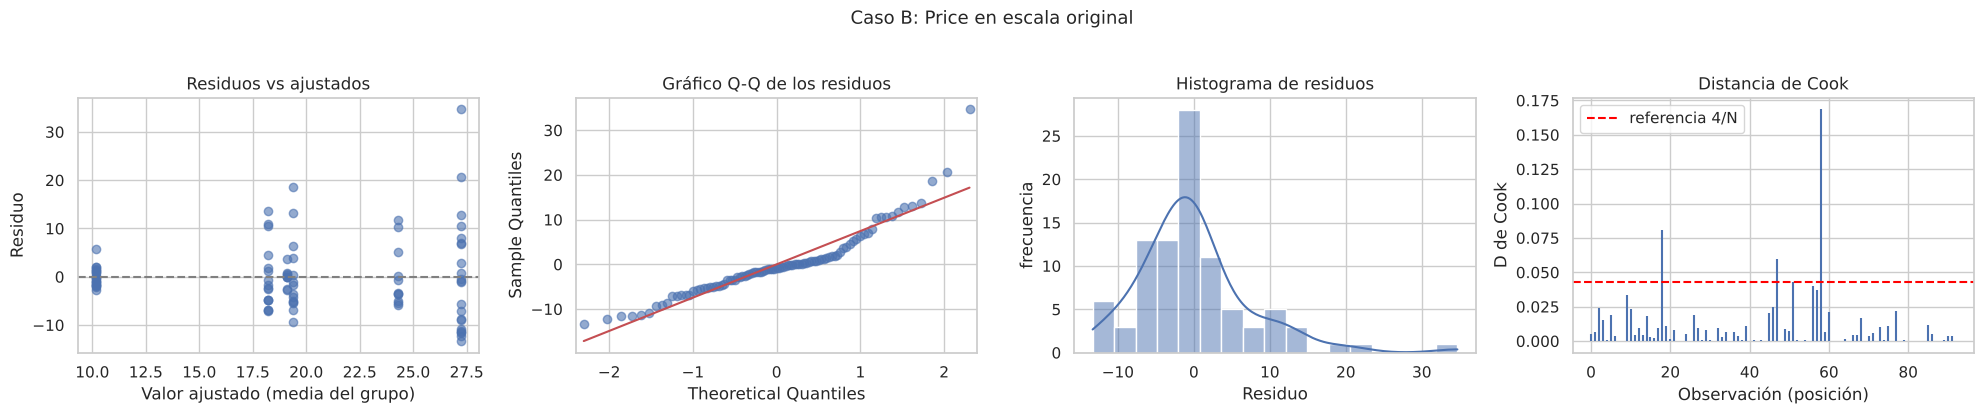

,prueba,estadistico,valor_p
0,Shapiro-Wilk (normalidad de residuos),0.8987,0.0000
1,Levene-mediana (igualdad de varianzas),5.8318,0.0001
2,"Bartlett (igualdad de varianzas, exige normali...",63.2624,0.0000
3,Fligner-Killeen (igualdad de varianzas),26.7362,0.0001


Cociente DE máxima / DE mínima entre grupos: 6.5
Residuos estudentizados con |r| > 3: 1


In [21]:
_ = diagnostico_anova(cars, "Price", "Type", "Caso B: Price en escala original")

**Interpretación del caso B en escala original.** Los problemas son evidentes: la columna de residuos de los medianos es mucho más ancha que la de los pequeños (heterocedasticidad), el gráfico Q-Q se curva hacia arriba en el extremo derecho (asimetría positiva) y aparece al menos un residuo estudentizado extremo. Las pruebas formales coinciden con los gráficos.

### Remedio 1: transformar la respuesta

Cuando la dispersión crece con la media y la distribución es asimétrica a la derecha, como suele ocurrir con precios, ingresos o tiempos, el logaritmo tiende a estabilizar la varianza y a simetrizar. Además tiene una interpretación natural: las diferencias en escala logarítmica son **cocientes** en la escala original.

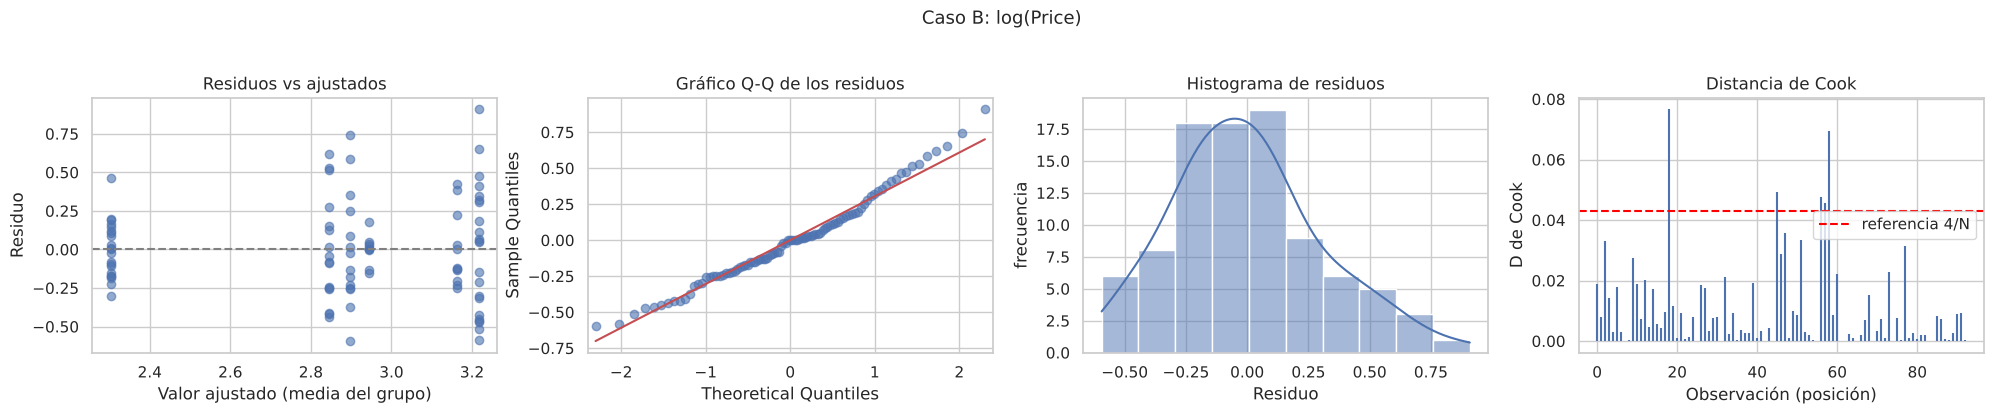

,prueba,estadistico,valor_p
0,Shapiro-Wilk (normalidad de residuos),0.9786,0.1299
1,Levene-mediana (igualdad de varianzas),4.5870,0.0009
2,"Bartlett (igualdad de varianzas, exige normali...",25.7826,0.0001
3,Fligner-Killeen (igualdad de varianzas),19.8376,0.0013


Cociente DE máxima / DE mínima entre grupos: 4.3
Residuos estudentizados con |r| > 3: 1


In [22]:
cars["log_precio"] = np.log(cars.Price)
modelo_cars_log = diagnostico_anova(cars, "log_precio", "Type", "Caso B: log(Price)")

**Interpretación.** En escala logarítmica el gráfico Q-Q mejora notablemente y Shapiro-Wilk ya no rechaza; el cociente entre desviaciones estándar baja de 6,5 a 4,3. Sin embargo, la heterogeneidad **no desaparece**: las *vans* son muy homogéneas entre sí y los medianos siguen siendo dispersos, y Levene sigue rechazando. La transformación mejoró la situación, pero no lo suficiente como para confiar ciegamente en la prueba $F$ clásica en un diseño desbalanceado. ¿Qué tan grave es? Respondemos con una simulación.

### Atípicos en el caso B

In [23]:
influencia_cars = modelo_cars_log.get_influence()
cars["res_estudentizado"] = influencia_cars.resid_studentized_external
cars["cook"] = influencia_cars.cooks_distance[0]
cars.nlargest(4, "cook")[["Manufacturer", "Model", "Type", "Price", "res_estudentizado", "cook"]].round(3)

,Manufacturer,Model,Type,Price,res_estudentizado,cook
19,Chevrolet,Corvette,Sporty,38.0,2.519,0.077
59,Mercedes-Benz,300E,Midsize,61.9,3.100,0.069
46,Hyundai,Scoupe,Sporty,10.0,-1.993,0.049
57,Mazda,RX-7,Sporty,32.5,1.960,0.048


In [24]:
# Análisis de sensibilidad: ¿cambia la conclusión si excluimos la observación más influyente?
indice_mas_influyente = cars.cook.idxmax()
sin_influyente = cars.drop(index=indice_mas_influyente)
tabla_sin = sm.stats.anova_lm(smf.ols("log_precio ~ C(Type)", data=sin_influyente).fit())
tabla_con = sm.stats.anova_lm(modelo_cars_log)
print(f"Con todos los modelos:   F = {tabla_con.F.iloc[0]:.2f}, p = {tabla_con['PR(>F)'].iloc[0]:.2e}")
print(f"Sin {cars.loc[indice_mas_influyente, 'Manufacturer']} {cars.loc[indice_mas_influyente, 'Model']}:  "
      f"F = {tabla_sin.F.iloc[0]:.2f}, p = {tabla_sin['PR(>F)'].iloc[0]:.2e}")

Con todos los modelos:   F = 21.04, p = 9.90e-14
Sin Chevrolet Corvette:  F = 22.31, p = 2.83e-14


**Interpretación.** El modelo más influyente corresponde a un vehículo de precio inusual dentro de su categoría. Es un dato legítimo, no un error, y por eso se conserva. El análisis de sensibilidad muestra que excluirlo no cambia la conclusión: la evidencia de diferencias entre tipos es igualmente fuerte.

## 4.6 Simulación 3: ¿qué tan grave es la heterocedasticidad?

> 🔮 **Pregunta de predicción.** Tres grupos tienen **la misma media**, pero desviaciones estándar 1, 2 y 4. Si el grupo **más pequeño** es el más disperso, ¿la prueba $F$ clásica rechazará $H_0$ más o menos del 5 % de las veces? ¿Y si el grupo más disperso es el **más grande**?

Comparamos la prueba $F$ clásica con la prueba de **Welch**, que estima una varianza distinta para cada grupo (su fórmula se presenta en la Unidad 6). Para que la simulación sea rápida implementamos ambas de forma vectorizada y verificamos primero que nuestra implementación de Welch coincide con la de `statsmodels`.

In [25]:
def F_clasica_y_welch(y, tamanos):
    '''Valores p de la F clásica y de Welch para un arreglo (repeticiones x N) con grupos contiguos de tamaños dados.'''
    limites = np.cumsum([0] + list(tamanos))
    grupos = [y[:, a:b] for a, b in zip(limites[:-1], limites[1:])]
    n_i = np.array(tamanos, dtype=float)
    k, N = len(tamanos), n_i.sum()
    medias_i = np.column_stack([g.mean(axis=1) for g in grupos])
    var_i = np.column_stack([g.var(axis=1, ddof=1) for g in grupos])
    # F clásica (varianza común)
    media_general = (medias_i * n_i).sum(axis=1) / N
    sc_entre = (n_i * (medias_i - media_general[:, None]) ** 2).sum(axis=1)
    sc_dentro = ((n_i - 1) * var_i).sum(axis=1)
    p_clasica = stats.f.sf((sc_entre / (k - 1)) / (sc_dentro / (N - k)), k - 1, N - k)
    # Welch (una varianza por grupo)
    w = n_i / var_i
    media_ponderada = (w * medias_i).sum(axis=1) / w.sum(axis=1)
    A = (w * (medias_i - media_ponderada[:, None]) ** 2).sum(axis=1) / (k - 1)
    lam = ((1 - w / w.sum(axis=1, keepdims=True)) ** 2 / (n_i - 1)).sum(axis=1)
    F_welch = A / (1 + 2 * (k - 2) * lam / (k ** 2 - 1))
    gl2_welch = (k ** 2 - 1) / (3 * lam)
    p_welch = stats.f.sf(F_welch, k - 1, gl2_welch)
    return p_clasica, p_welch, F_welch, gl2_welch

# Verificación contra statsmodels con los datos de Cars93 (log del precio)
orden_cars = cars.sort_values("Type")
tamanos_cars = orden_cars.groupby("Type", observed=True).size().values
_, p_welch_propio, F_welch_propio, gl2_propio = F_clasica_y_welch(orden_cars.log_precio.values[None, :], tamanos_cars)
welch_statsmodels = anova_oneway(cars.log_precio, cars.Type, use_var="unequal")
print(f"Welch implementado: F = {F_welch_propio[0]:.4f}, gl2 = {gl2_propio[0]:.2f}, p = {p_welch_propio[0]:.3e}")
print(f"Welch statsmodels:  F = {welch_statsmodels.statistic:.4f}, gl2 = {welch_statsmodels.df_denom:.2f}, p = {welch_statsmodels.pvalue:.3e}")

Welch implementado: F = 41.6834, gl2 = 36.80, p = 3.631e-14
Welch statsmodels:  F = 41.6834, gl2 = 36.80, p = 3.631e-14


In [26]:
def error_tipo_I(tamanos, desviaciones, repeticiones=20000, alfa=0.05, semilla=SEMILLA):
    '''Tasa de rechazo de H0 (verdadera: medias iguales) para la F clásica y para Welch.'''
    gen = np.random.default_rng(semilla)
    y = np.hstack([gen.normal(0, s, size=(repeticiones, n)) for n, s in zip(tamanos, desviaciones)])
    p_clasica, p_welch, _, _ = F_clasica_y_welch(y, tamanos)
    return np.mean(p_clasica < alfa), np.mean(p_welch < alfa)

escenarios_robustez = {
    "A. Supuestos cumplidos (n iguales, σ iguales)": ([20, 20, 20], [1, 1, 1]),
    "B. σ distintas, n iguales": ([20, 20, 20], [1, 2, 4]),
    "C. σ distintas; el grupo GRANDE es el más disperso": ([10, 20, 40], [1, 2, 4]),
    "D. σ distintas; el grupo PEQUEÑO es el más disperso": ([10, 20, 40], [4, 2, 1]),
    "E. n distintos, σ iguales": ([10, 20, 40], [1, 1, 1]),
}
filas_robustez = []
for nombre, (tamanos, desviaciones) in escenarios_robustez.items():
    tasa_clasica, tasa_welch = error_tipo_I(tamanos, desviaciones)
    filas_robustez.append({"escenario": nombre, "n por grupo": tamanos, "σ por grupo": desviaciones,
                           "error tipo I: F clásica": tasa_clasica, "error tipo I: Welch": tasa_welch})
tabla_robustez = pd.DataFrame(filas_robustez)
tabla_robustez.round(3)

,escenario,n por grupo,σ por grupo,error tipo I: F clásica,error tipo I: Welch
0,"A. Supuestos cumplidos (n iguales, σ iguales)","[20, 20, 20]","[1, 1, 1]",0.047,0.048
1,"B. σ distintas, n iguales","[20, 20, 20]","[1, 2, 4]",0.068,0.048
2,C. σ distintas; el grupo GRANDE es el más disp...,"[10, 20, 40]","[1, 2, 4]",0.010,0.051
3,D. σ distintas; el grupo PEQUEÑO es el más dis...,"[10, 20, 40]","[4, 2, 1]",0.243,0.053
4,"E. n distintos, σ iguales","[10, 20, 40]","[1, 1, 1]",0.051,0.052


**Interpretación.** Con 20 000 repeticiones, el error de Monte Carlo de cada tasa es del orden de $\pm0{,}003$, de modo que las diferencias observadas no se deben al azar de la simulación.

- **A y E:** cuando la varianza es común, ambas pruebas rechazan alrededor del 5 %: están **calibradas**, aun con tamaños de grupo distintos.
- **B:** con diseño **balanceado**, la $F$ clásica se aparta poco del 5 % aunque las varianzas difieran: es la razón por la que se dice que el ANOVA es robusto a la heterocedasticidad *cuando los grupos tienen el mismo tamaño*.
- **C:** si el grupo grande es el más disperso, la $F$ clásica se vuelve **conservadora**: rechaza mucho menos del 5 % y pierde potencia.
- **D:** si el grupo **pequeño** es el más disperso, la $F$ clásica se vuelve **liberal**: rechaza una hipótesis nula verdadera alrededor de una de cada cuatro veces, cinco veces más de lo prometido. Sus "descubrimientos" no son confiables.
- La prueba de **Welch** se mantiene cerca del 5 % en todos los escenarios.

Esta es la rigidez de la estructura paramétrica en acción: el valor $p$ de la $F$ clásica es una promesa que **sólo se cumple si el modelo es correcto**. La teoría explica el patrón: el denominador de $F$ promedia las varianzas ponderándolas por los grados de libertad de cada grupo, de modo que el grupo grande domina la estimación de $\sigma^2$.

✏️ **Experimente:** agregue el escenario `([5, 5, 50], [3, 1, 1])`. Antes de ejecutar, prediga si la $F$ clásica será liberal o conservadora.

## 4.7 ¿Cuándo usar ANOVA clásico y cuándo Welch?

| Situación | Recomendación |
|---|---|
| Diseño balanceado, dispersiones similares (cociente de DE menor que 2 aproximadamente) | ANOVA clásico; Welch daría la misma conclusión |
| Diseño balanceado con heterogeneidad moderada | ANOVA clásico es razonablemente robusto; reportar Welch como verificación es buena práctica |
| Diseño **desbalanceado** con varianzas distintas | **Welch**, porque la $F$ clásica puede ser liberal o conservadora |
| Duda | Welch: cuando las varianzas son iguales pierde muy poca potencia frente a la $F$ clásica |

Una práctica que se ha difundido en la literatura metodológica reciente es usar Welch **por defecto** en lugar de decidir a partir de una prueba previa de Levene, porque esa decisión en dos etapas altera las tasas de error. Para `Cars93`, con diseño desbalanceado y heterogeneidad persistente, Welch es la elección adecuada.

In [27]:
tabla_cars_log = sm.stats.anova_lm(modelo_cars_log)
pd.DataFrame({
    "prueba": ["F clásica (log precio)", "Welch (log precio)"],
    "estadistico": [tabla_cars_log.F.iloc[0], welch_statsmodels.statistic],
    "gl numerador": [5, welch_statsmodels.df_num],
    "gl denominador": [tabla_cars_log.df.iloc[1], welch_statsmodels.df_denom],
    "valor_p": [tabla_cars_log["PR(>F)"].iloc[0], welch_statsmodels.pvalue],
}).round(4)

,prueba,estadistico,gl numerador,gl denominador,valor_p
0,F clásica (log precio),21.0444,5.0,87.0000,0.0
1,Welch (log precio),41.6834,5.0,36.8005,0.0


**Conclusión del caso B tras el diagnóstico.** Ambas pruebas llevan a la misma decisión. Una redacción adecuada sería:

> *En los 93 modelos de 1993 analizados, el precio (en escala logarítmica) difiere según el tipo de vehículo, ANOVA de Welch $F(5;\,36{,}8)=41{,}7$, $p<0{,}001$. Se utilizó la prueba de Welch porque el diseño es desbalanceado y las varianzas difieren entre tipos aun después de la transformación logarítmica. Al tratarse de datos observacionales, la diferencia indica una asociación entre tipo y precio y no un efecto causal del tipo.*

🤔 **Reflexión 4.1.** Un compañero argumenta: "Shapiro-Wilk dio $p=0{,}13$ con el logaritmo, así que los datos son normales". Escriba en dos frases por qué esa afirmación es incorrecta y cómo la reformularía.

---
# Unidad 5. Comparaciones múltiples y tamaños del efecto

## 5.1 ANOVA significativo y ANOVA no significativo

> **Pregunta orientadora.** El ANOVA nos dijo que "algo difiere". ¿Qué hacemos ahora? ¿Y qué hacemos si el ANOVA no es significativo?

Si el ANOVA es **significativo**, el paso siguiente es localizar las diferencias con un procedimiento que controle el error por familia y estimar su magnitud con intervalos de confianza.

Si el ANOVA **no** es significativo, la tentación de "buscar" alguna comparación significativa debe resistirse: es la misma inflación del error de tipo I que vimos en la Unidad 1. Además, un resultado no significativo **no demuestra** que las medias sean iguales: puede deberse a falta de potencia. Lo correcto es reportar las medias, los intervalos de confianza de las diferencias y el tamaño del efecto, para que el lector vea qué magnitudes son compatibles con los datos. Veamos un ejemplo con tres tipos de `Cars93` que, como se verá, no difieren de manera significativa.

In [28]:
tres_tipos = cars[cars.Type.isin(["Compact", "Sporty", "Van"])].copy()
tres_tipos["Type"] = tres_tipos.Type.cat.remove_unused_categories()
anova_tres = sm.stats.anova_lm(smf.ols("log_precio ~ C(Type)", data=tres_tipos).fit())
print(anova_tres.round(4))
diferencias = []
for tipo_a, tipo_b in combinations(tres_tipos.Type.cat.categories, 2):
    a = tres_tipos.loc[tres_tipos.Type == tipo_a, "log_precio"]
    b = tres_tipos.loc[tres_tipos.Type == tipo_b, "log_precio"]
    welch_par = stats.ttest_ind(b, a, equal_var=False)
    ic = welch_par.confidence_interval()
    diferencias.append({"comparación": f"{tipo_b} − {tipo_a}", "diferencia log": b.mean() - a.mean(),
                        "IC95% inferior": ic.low, "IC95% superior": ic.high,
                        "cociente de precios": np.exp(b.mean() - a.mean()),
                        "cociente IC inf": np.exp(ic.low), "cociente IC sup": np.exp(ic.high)})
pd.DataFrame(diferencias).round(3)

            df  sum_sq  mean_sq       F  PR(>F)
C(Type)    2.0  0.0611   0.0305  0.2999  0.7427
Residual  36.0  3.6656   0.1018     NaN     NaN


,comparación,diferencia log,IC95% inferior,IC95% superior,cociente de precios,cociente IC inf,cociente IC sup
0,Sporty − Compact,0.052,-0.218,0.323,1.054,0.804,1.381
1,Van − Compact,0.101,-0.092,0.294,1.106,0.912,1.342
2,Van − Sporty,0.049,-0.174,0.272,1.050,0.840,1.312


**Interpretación.** El ANOVA no es significativo ($p\approx0{,}75$). Pero observe los intervalos: un deportivo podría costar desde alrededor de un 20 % menos hasta casi un 40 % más que un compacto, y una *van* desde un 10 % menos hasta un 34 % más. Los datos son compatibles tanto con la ausencia de diferencias como con diferencias de precio importantes desde el punto de vista comercial. "No encontramos evidencia de diferencias" es la conclusión correcta; "los tres tipos cuestan lo mismo" no lo es. (Los intervalos de esta tabla son individuales y no están ajustados por multiplicidad: sirven para describir la incertidumbre, no para declarar significancia.)

## 5.2 Tukey HSD: todas las comparaciones por pares con varianza común

El procedimiento de **Tukey HSD** (*honestly significant difference*), en la versión de Tukey-Kramer para tamaños distintos, compara todos los pares de medias usando la distribución del **rango estudentizado** $q$. Para el par $(i,j)$:

$$
\left|\bar y_{i\cdot}-\bar y_{j\cdot}\right| > \frac{q_{1-\alpha;\,k,\,N-k}}{\sqrt 2}\;\sqrt{CM_E\left(\frac{1}{n_i}+\frac{1}{n_j}\right)} .
$$

Controla la FWER en $\alpha$ para el conjunto de todas las comparaciones por pares y produce intervalos de confianza **simultáneos**. Como usa $CM_E$, **supone varianza común**: es el procedimiento natural después de un ANOVA clásico cuyos supuestos se cumplen. Por eso lo aplicamos al caso A.

In [29]:
tukey_produccion = pairwise_tukeyhsd(produccion.tiempo_min, produccion.metodo.astype(str), alpha=0.05)
tabla_tukey_produccion = pd.DataFrame(tukey_produccion.summary().data[1:], columns=tukey_produccion.summary().data[0])
tabla_tukey_produccion["comparación"] = tabla_tukey_produccion.group2 + " − " + tabla_tukey_produccion.group1
tabla_tukey_produccion[["comparación", "meandiff", "lower", "upper", "p-adj", "reject"]]

,comparación,meandiff,lower,upper,p-adj,reject
0,B_semiautomatico − A_actual,-3.85,-6.5916,-1.1084,0.0047,True
1,C_celda_U − A_actual,-4.07,-6.8116,-1.3284,0.0028,True
2,C_celda_U − B_semiautomatico,-0.22,-2.9616,2.5216,0.9784,False


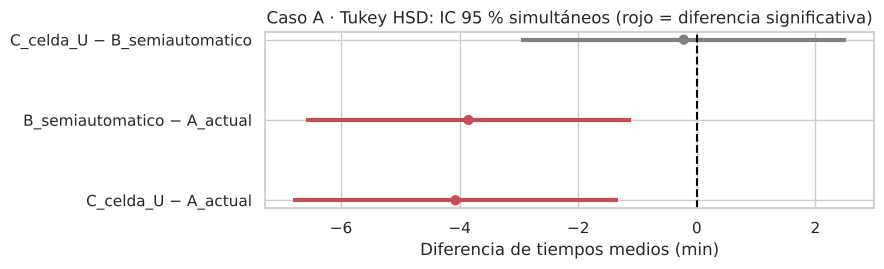

In [30]:
def grafico_comparaciones(tabla, columna_dif, columna_inf, columna_sup, columna_rechazo, titulo, etiqueta_x):
    '''Intervalos de confianza simultáneos; en rojo los pares cuyo intervalo excluye el cero.'''
    tabla = tabla.sort_values(columna_dif)
    colores = np.where(tabla[columna_rechazo], "C3", "gray")
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(tabla) + 1.5))
    ax.hlines(tabla["comparación"], tabla[columna_inf], tabla[columna_sup], color=colores, lw=3)
    ax.scatter(tabla[columna_dif], tabla["comparación"], color=colores, zorder=3, s=40)
    ax.axvline(0, ls="--", color="black")
    ax.set(xlabel=etiqueta_x, title=titulo)
    plt.tight_layout(); plt.show()

grafico_comparaciones(tabla_tukey_produccion, "meandiff", "lower", "upper", "reject",
                      "Caso A · Tukey HSD: IC 95 % simultáneos (rojo = diferencia significativa)",
                      "Diferencia de tiempos medios (min)")

**Interpretación.** Los métodos semiautomático (B) y celda en U (C) reducen el tiempo medio en unos 4 minutos respecto al método actual; los intervalos simultáneos van aproximadamente de 1 a 7 minutos. Entre B y C no se detecta diferencia: el intervalo incluye el cero y es compatible con diferencias de hasta unos 3 minutos en cualquiera de las dos direcciones. Para la gerencia, esto significa que cualquiera de los dos métodos nuevos mejora el actual, y que la elección entre B y C puede basarse en costos, ergonomía o inversión, salvo que se quiera un estudio adicional con más potencia para compararlos.

## 5.3 Games-Howell: comparaciones por pares con varianzas desiguales

Cuando las varianzas difieren, Tukey hereda el problema de la $F$ clásica. El procedimiento de **Games-Howell** es el equivalente de Welch para las comparaciones por pares: cada comparación usa su propio error estándar y sus propios grados de libertad (de Welch-Satterthwaite), y el valor crítico se toma de la distribución del rango estudentizado:

$$
t_{ij}=\frac{\bar y_{j\cdot}-\bar y_{i\cdot}}{\sqrt{\dfrac{s_i^2}{n_i}+\dfrac{s_j^2}{n_j}}},\qquad
\nu_{ij}=\frac{\left(\dfrac{s_i^2}{n_i}+\dfrac{s_j^2}{n_j}\right)^2}{\dfrac{(s_i^2/n_i)^2}{n_i-1}+\dfrac{(s_j^2/n_j)^2}{n_j-1}},\qquad
p_{ij}=P\!\left(q_{k,\nu_{ij}}\ge\sqrt2\,|t_{ij}|\right).
$$

`statsmodels` no incluye Games-Howell, así que lo implementamos directamente con la distribución del rango estudentizado de `scipy`. Es la elección adecuada para el caso B.

In [31]:
def games_howell(datos, respuesta, factor, alfa=0.05):
    '''Comparaciones por pares de Games-Howell (no supone varianzas iguales).'''
    resumen = datos.groupby(factor, observed=True)[respuesta].agg(["mean", "var", "count"])
    k = len(resumen)
    filas = []
    for grupo_i, grupo_j in combinations(resumen.index, 2):
        mi, vi, ni = resumen.loc[grupo_i]
        mj, vj, nj = resumen.loc[grupo_j]
        diferencia = mj - mi
        error_estandar = np.sqrt(vi / ni + vj / nj)
        gl = (vi / ni + vj / nj) ** 2 / ((vi / ni) ** 2 / (ni - 1) + (vj / nj) ** 2 / (nj - 1))
        t = diferencia / error_estandar
        p = stats.studentized_range.sf(np.sqrt(2) * abs(t), k, gl)
        q_crit = stats.studentized_range.ppf(1 - alfa, k, gl)
        semiancho = q_crit / np.sqrt(2) * error_estandar
        filas.append({"comparación": f"{grupo_j} − {grupo_i}", "diferencia": diferencia, "gl": gl,
                      "IC inferior": diferencia - semiancho, "IC superior": diferencia + semiancho,
                      "p ajustado": p, "significativa": p < alfa})
    return pd.DataFrame(filas)

gh_cars = games_howell(cars, "log_precio", "Type")
gh_cars["cociente de precios"] = np.exp(gh_cars.diferencia)
gh_cars.round(4)

,comparación,diferencia,gl,IC inferior,IC superior,p ajustado,significativa,cociente de precios
0,Compact − Small,0.5414,21.3257,0.2454,0.8375,0.0001,True,1.7185
1,Midsize − Small,0.9139,28.8892,0.6154,1.2124,0.0000,True,2.4941
2,Large − Small,0.8597,16.1156,0.5930,1.1265,0.0000,True,2.3625
3,Sporty − Small,0.5936,17.1579,0.2507,0.9366,0.0004,True,1.8105
4,Van − Small,0.6425,26.1330,0.4844,0.8006,0.0000,True,1.9013
5,Midsize − Compact,0.3725,35.4064,-0.0014,0.7464,0.0514,False,1.4513
6,Large − Compact,0.3183,24.9709,-0.0290,0.6656,0.0862,False,1.3748
7,Sporty − Compact,0.0522,26.7264,-0.3517,0.4561,0.9986,False,1.0536
8,Van − Compact,0.1011,18.9292,-0.1901,0.3922,0.8764,False,1.1064
9,Large − Midsize,-0.0542,30.2155,-0.4048,0.2964,0.9969,False,0.9473


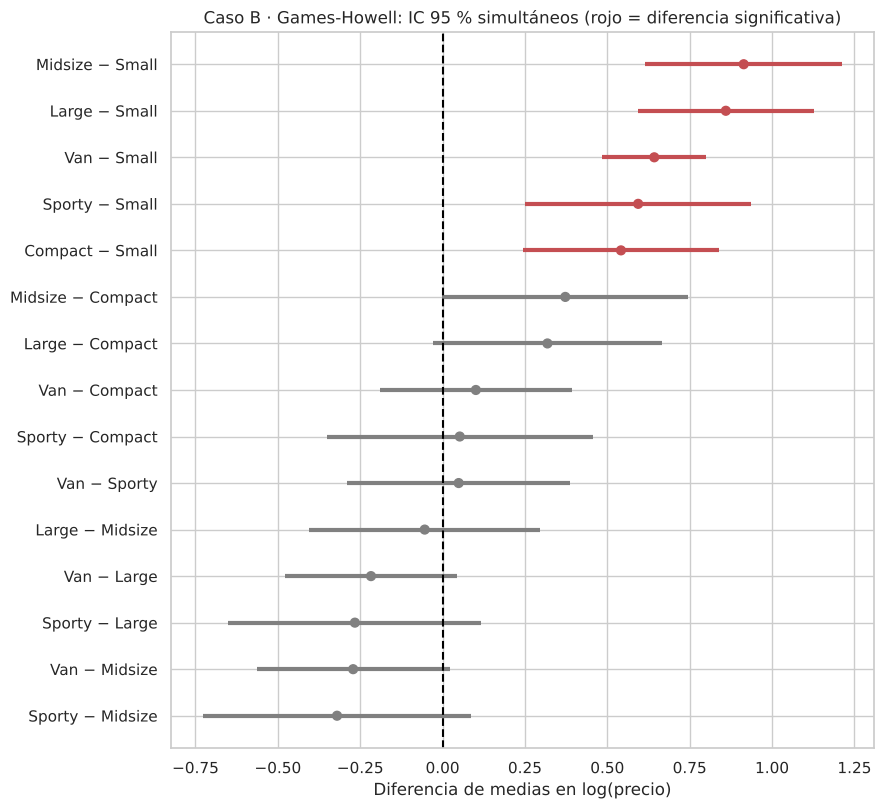

In [32]:
grafico_comparaciones(gh_cars, "diferencia", "IC inferior", "IC superior", "significativa",
                      "Caso B · Games-Howell: IC 95 % simultáneos (rojo = diferencia significativa)",
                      "Diferencia de medias en log(precio)")

In [33]:
# Comparación de decisiones: Tukey (varianza común) frente a Games-Howell (varianzas desiguales)
tukey_cars = pairwise_tukeyhsd(cars.log_precio, cars.Type.astype(str), alpha=0.05)
tabla_tukey_cars = pd.DataFrame(tukey_cars.summary().data[1:], columns=tukey_cars.summary().data[0])
tabla_tukey_cars["par"] = tabla_tukey_cars.apply(lambda f: frozenset([f.group1, f.group2]), axis=1)
gh_cars["par"] = gh_cars["comparación"].str.split(" − ").apply(frozenset)
comparacion_metodos = gh_cars.merge(tabla_tukey_cars[["par", "p-adj"]], on="par")
comparacion_metodos = comparacion_metodos.rename(columns={"p ajustado": "p Games-Howell", "p-adj": "p Tukey"})
comparacion_metodos["decisiones distintas"] = (comparacion_metodos["p Games-Howell"] < 0.05) != (comparacion_metodos["p Tukey"] < 0.05)
comparacion_metodos[["comparación", "p Tukey", "p Games-Howell", "decisiones distintas"]].round(4)

,comparación,p Tukey,p Games-Howell,decisiones distintas
0,Compact − Small,0.0000,0.0001,False
1,Midsize − Small,0.0000,0.0000,False
2,Large − Small,0.0000,0.0000,False
3,Sporty − Small,0.0000,0.0004,False
4,Van − Small,0.0000,0.0000,False
5,Midsize − Compact,0.0067,0.0514,True
6,Large − Compact,0.1124,0.0862,False
7,Sporty − Compact,0.9975,0.9986,False
8,Van − Compact,0.9717,0.8764,False
9,Large − Midsize,0.9972,0.9969,False


**Interpretación.** Una diferencia $d$ en logaritmos corresponde a un cociente $e^{d}$ entre medias geométricas de precios. Así, la diferencia *Midsize − Small* de aproximadamente 0,91 significa que un mediano cuesta en promedio unas $e^{0{,}91}\approx2{,}5$ veces lo que cuesta un pequeño. Con Games-Howell, los pequeños son más baratos que todos los demás tipos y ninguna otra comparación alcanza significancia.

La tabla comparativa muestra que Tukey y Games-Howell no siempre coinciden. Las dos discrepancias (*Midsize − Compact* y *Sporty − Midsize*) involucran a los medianos, el grupo más disperso. Tukey usa una única varianza combinada para todos los pares, que **subestima** la incertidumbre de las comparaciones con un grupo tan variable y por eso las declara significativas. Games-Howell usa la varianza propia de cada grupo: el error estándar de esas comparaciones es mayor y la evidencia deja de ser concluyente. Con varianzas desiguales y grupos de distinto tamaño, los resultados de Games-Howell son los que deben reportarse; los de Tukey serían demasiado optimistas en estos pares.

### Guía para elegir el procedimiento

| Situación | Procedimiento |
|---|---|
| Todos los pares, varianzas homogéneas | **Tukey HSD** (Tukey-Kramer si $n_i$ distintos) |
| Todos los pares, varianzas heterogéneas | **Games-Howell** |
| Cada tratamiento contra un control | **Dunnett** |
| Pocas comparaciones definidas de antemano | **Contrastes planeados** con Bonferroni o Holm |
| Muchas pruebas exploratorias (decenas o cientos) | Control de la tasa de falsos descubrimientos (Benjamini-Hochberg) |

## 5.4 Contrastes planeados

Si **antes** de ver los datos se tiene una pregunta concreta, se formula como un **contraste** $L=\sum_i c_i\mu_i$ con $\sum_i c_i=0$. Por ejemplo, en el caso A la gerencia podría haber preguntado: *¿los métodos nuevos (B y C), en promedio, reducen el tiempo frente al actual?*

$$
L=\tfrac12(\mu_B+\mu_C)-\mu_A .
$$

El estimador es $\hat L=\sum c_i\bar y_{i\cdot}$, con error estándar $\sqrt{CM_E\sum c_i^2/n_i}$, y se contrasta con una distribución $t$ con $N-k$ grados de libertad. Un contraste planeado responde exactamente la pregunta de interés con más potencia que una batería de comparaciones *post hoc*.

In [34]:
modelo_medias_celda = smf.ols("tiempo_min ~ C(metodo) - 1", data=produccion).fit()   # un parámetro por media
print(modelo_medias_celda.params.round(3).to_string(), "\n")
coeficientes_contraste = np.array([-1, 0.5, 0.5])                                    # orden: A, B, C
contraste_nuevos = modelo_medias_celda.t_test(coeficientes_contraste)
print(contraste_nuevos)

C(metodo)[A_actual]            41.63
C(metodo)[B_semiautomatico]    37.78
C(metodo)[C_celda_U]           37.56 

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0            -3.9600      0.958     -4.135      0.000      -5.925      -1.995


**Interpretación.** En promedio, los métodos nuevos reducen el tiempo en unos 4 minutos respecto al actual (IC 95 % aproximado de 2,0 a 5,9 minutos). Como el contraste se planteó antes de mirar los datos y es una sola prueba, no requiere ajuste por multiplicidad. Si se plantean varios contrastes, se aplica Bonferroni o Holm a sus valores $p$ (función `multipletests` de `statsmodels`).

## 5.5 Tamaños del efecto

> **Pregunta orientadora.** Un valor $p$ diminuto, ¿significa que la diferencia es grande?

No necesariamente. El valor $p$ mezcla dos cosas: la magnitud del efecto y el tamaño de la muestra. Con muestras enormes, diferencias triviales producen valores $p$ minúsculos. Por eso se reportan **tamaños del efecto**, que miden la magnitud independientemente de $n$.

**Eta cuadrado** es la proporción de la variabilidad total explicada por el factor; coincide con el $R^2$ del modelo:

$$
\eta^2=\frac{SC_{Tr}}{SC_T}.
$$

Es un estimador **sesgado hacia arriba** de la proporción poblacional, sobre todo con muestras pequeñas y muchos grupos, porque una parte de $SC_{Tr}$ se debe al azar. **Omega cuadrado** corrige ese sesgo (para un factor de efectos fijos):

$$
\omega^2=\frac{SC_{Tr}-(k-1)\,CM_E}{SC_T+CM_E}.
$$

Puede resultar ligeramente negativo cuando el efecto es nulo; en ese caso se reporta como 0. La **$f$ de Cohen** expresa la razón entre la dispersión de las medias y la dispersión dentro de los grupos, y es la medida que usan los cálculos de potencia:

$$
f=\sqrt{\frac{\eta^2}{1-\eta^2}}\quad(\text{versión muestral; con }\omega^2\text{ en lugar de }\eta^2\text{ se obtiene una versión menos sesgada}).
$$

**Sobre los umbrales.** Cohen (1988) propuso, para la investigación en ciencias del comportamiento, valores de referencia de $f=0{,}10$, $0{,}25$ y $0{,}40$ (equivalentes aproximadamente a $\eta^2=0{,}01$, $0{,}06$ y $0{,}14$) para efectos "pequeños", "medianos" y "grandes". El propio Cohen advirtió que eran convenciones para cuando no se dispone de nada mejor. En un contexto aplicado la importancia de un efecto se juzga en **unidades del problema**: en la planta, 4 minutos por orden multiplicados por el número de órdenes anuales es lo que decide si el cambio de método vale la pena, no la etiqueta "grande".

In [35]:
def tamanos_del_efecto(tabla_anova):
    '''η², ω² y f de Cohen a partir de una tabla anova_lm de un factor (fila 0: factor, fila 1: residuo).'''
    sc_factor, sc_error = tabla_anova.sum_sq.iloc[0], tabla_anova.sum_sq.iloc[1]
    gl_factor = tabla_anova.df.iloc[0]
    cm_error = tabla_anova.mean_sq.iloc[1]
    sc_total = sc_factor + sc_error
    eta2 = sc_factor / sc_total
    omega2 = max(0.0, (sc_factor - gl_factor * cm_error) / (sc_total + cm_error))
    return {"eta²": eta2, "omega²": omega2, "f de Cohen (con η²)": np.sqrt(eta2 / (1 - eta2)),
            "f de Cohen (con ω²)": np.sqrt(omega2 / (1 - omega2))}

pd.DataFrame({
    "Ejemplo a mano": tamanos_del_efecto(sm.stats.anova_lm(modelo_mano)),
    "Caso A: producción": tamanos_del_efecto(tabla_produccion),
    "Caso B: log(precio) por tipo": tamanos_del_efecto(tabla_cars_log),
    "Compact/Sporty/Van": tamanos_del_efecto(anova_tres),
}).T.round(3)

,eta²,omega²,f de Cohen (con η²),f de Cohen (con ω²)
Ejemplo a mano,0.706,0.620,1.549,1.278
Caso A: producción,0.388,0.335,0.797,0.710
Caso B: log(precio) por tipo,0.547,0.519,1.100,1.038
Compact/Sporty/Van,0.016,0.000,0.129,0.000


**Interpretación.** En el ejemplo a mano $\eta^2=72/102\approx0{,}71$, pero con sólo 12 observaciones $\omega^2$ lo corrige a la baja de manera apreciable: buena parte de la variabilidad "explicada" en muestras pequeñas es optimismo. En `Cars93` el tipo de vehículo explica alrededor de la mitad de la variabilidad del logaritmo del precio. En el subconjunto de tres tipos $\omega^2=0$: no hay indicio de un efecto apreciable, aunque los intervalos de la sección 5.1 recuerdan que tampoco podemos descartarlo.

## 5.6 Significancia estadística frente a importancia práctica: potencia y tamaño de muestra

### Simulación 4: el tamaño de muestra y la potencia

> 🔮 **Pregunta de predicción.** Tres métodos difieren en 1 minuto en promedio (medias 40, 40,5 y 41, con $\sigma=3$). Con 10 órdenes por método, ¿qué probabilidad hay de detectar la diferencia? ¿Cuántas órdenes por método harían falta para detectarla con probabilidad 0,8?

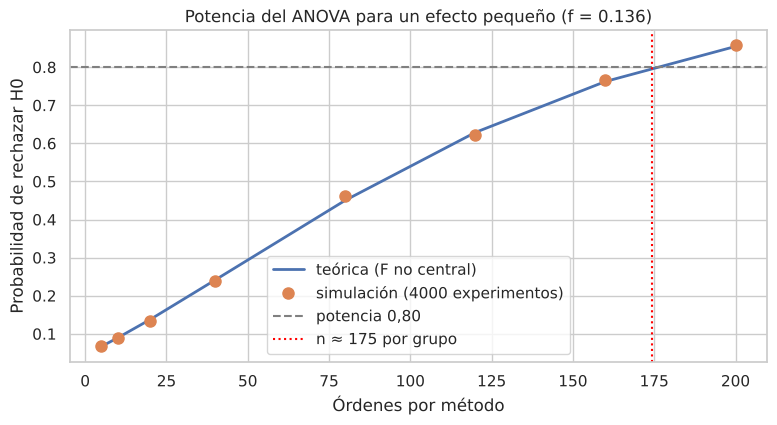

,n por grupo,potencia simulada,potencia teórica
0,5,0.068,0.067
1,10,0.090,0.089
2,20,0.134,0.138
3,40,0.239,0.241
4,80,0.463,0.451
5,120,0.622,0.629
6,160,0.766,0.762
7,200,0.857,0.854


In [36]:
medias_potencia, sigma_potencia, alfa = [40, 40.5, 41], 3, 0.05
tamanos_por_grupo = [5, 10, 20, 40, 80, 120, 160, 200]
# Tamaño del efecto poblacional f de Cohen: DE de las medias (con divisor k) / sigma
f_poblacional = np.std(medias_potencia) / sigma_potencia
potencia_teorica = FTestAnovaPower()

filas_potencia = []
for n in tamanos_por_grupo:
    valores_F = simular_F(medias_potencia, sigma_potencia, n, repeticiones=4000)
    filas_potencia.append({
        "n por grupo": n,
        "potencia simulada": np.mean(valores_F > stats.f.ppf(1 - alfa, 2, 3 * (n - 1))),
        "potencia teórica": potencia_teorica.power(effect_size=f_poblacional, nobs=3 * n, alpha=alfa, k_groups=3),
    })
tabla_potencia = pd.DataFrame(filas_potencia)
n_requerido = potencia_teorica.solve_power(effect_size=f_poblacional, alpha=alfa, power=0.80, k_groups=3)

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(tabla_potencia["n por grupo"], tabla_potencia["potencia teórica"], "-", lw=2, label="teórica (F no central)")
ax.plot(tabla_potencia["n por grupo"], tabla_potencia["potencia simulada"], "o", ms=8, label="simulación (4000 experimentos)")
ax.axhline(0.8, ls="--", color="gray", label="potencia 0,80")
ax.axvline(n_requerido / 3, ls=":", color="red", label=f"n ≈ {np.ceil(n_requerido / 3):.0f} por grupo")
ax.set(xlabel="Órdenes por método", ylabel="Probabilidad de rechazar H0",
       title=f"Potencia del ANOVA para un efecto pequeño (f = {f_poblacional:.3f})")
ax.legend(); plt.show()
tabla_potencia.round(3)

**Interpretación.** Con 10 órdenes por método la probabilidad de detectar una diferencia de 1 minuto es apenas cercana al 10 %: un experimento así está casi condenado a "no encontrar nada". Se necesitarían cerca de 175 órdenes por método para alcanzar una potencia de 0,8. La curva teórica se obtiene de la distribución $F$ no central y es una propiedad exacta bajo el modelo; los puntos simulados la reproducen con error de Monte Carlo.

La lección tiene dos caras. Antes del estudio, el cálculo de potencia permite dimensionar el experimento. Después del estudio, un resultado no significativo con baja potencia no es evidencia de ausencia de efecto. Y a la inversa: con unas 175 órdenes por método detectaríamos la diferencia de 1 minuto con probabilidad 0,8, pero la decisión de si 1 minuto **importa** es técnica y económica, no estadística.

🤔 **Reflexión 5.1.** Si la diferencia que le interesa a la gerencia fuera de 3 minutos (medias 40, 41,5 y 43), ¿cuántas órdenes por método bastarían? Use `potencia_teorica.solve_power`.

---
# Unidad 6. Alternativas y extensiones

El ANOVA de un factor es el caso más sencillo de una familia amplia. Esta unidad presenta, con distinta profundidad, las alternativas cuando fallan los supuestos y las extensiones a diseños más ricos. Cada extensión **añade estructura** para representar mejor la realidad, y cada estructura nueva trae sus propios supuestos.

## 6.1 ANOVA de Welch

Welch (1951) sustituye la varianza común por una varianza para cada grupo. Con pesos $w_i=n_i/s_i^2$ y media ponderada $\tilde y=\sum w_i\bar y_{i\cdot}/\sum w_i$,

$$
F_W=\frac{\dfrac{1}{k-1}\sum_i w_i(\bar y_{i\cdot}-\tilde y)^2}{1+\dfrac{2(k-2)}{k^2-1}\Lambda},\qquad
\Lambda=\sum_i\frac{\left(1-w_i/\sum_j w_j\right)^2}{n_i-1},
$$

que se compara con una distribución $F$ con $k-1$ y $(k^2-1)/(3\Lambda)$ grados de libertad. Ya la usamos en la Unidad 4: mantiene el error de tipo I cerca del nominal cuando las varianzas difieren, y pierde muy poca potencia cuando no difieren. Sigue suponiendo **independencia** y una normalidad aproximada dentro de cada grupo.

## 6.2 Kruskal-Wallis: qué contrasta realmente

La prueba de Kruskal-Wallis reemplaza los datos por sus **rangos** (posiciones al ordenar todas las observaciones) y compara los rangos promedio de los grupos:

$$
H=\frac{12}{N(N+1)}\sum_{i=1}^{k}n_i\left(\bar R_i-\frac{N+1}{2}\right)^2\;\overset{\text{aprox.}}{\sim}\;\chi^2_{k-1}\ \text{bajo } H_0 .
$$

Su hipótesis nula no es la igualdad de medias: es que **las $k$ poblaciones tienen la misma distribución**. La alternativa, en su forma general, es que al menos una población tiende a producir valores sistemáticamente mayores o menores que otra (dominancia estocástica). Sólo bajo el supuesto adicional de que todas las distribuciones tienen **la misma forma y la misma dispersión**, y difieren únicamente en su ubicación, el resultado puede leerse como una comparación de medianas.

De ahí sus limitaciones:

- **No es un sustituto automático** del ANOVA cuando falla la normalidad. Responde una pregunta distinta, y con muestras moderadas el ANOVA (o Welch) suele seguir siendo válido.
- **No resuelve la heterocedasticidad**: si los grupos tienen dispersiones distintas, puede rechazar $H_0$ aunque las medianas sean iguales, porque las distribuciones son distintas.
- No produce directamente una estimación de **cuánto** difieren los grupos en las unidades de la variable.

Es una buena opción cuando la respuesta es **ordinal**, cuando hay atípicos severos que no se pueden tratar, o cuando interesa precisamente la comparación de distribuciones. Si se rechaza, las comparaciones por pares se hacen con la prueba de Dunn u otras pruebas de rangos con ajuste por multiplicidad.

In [37]:
grupos_precio = [g.Price.values for _, g in cars.groupby("Type", observed=True)]
kruskal_cars = stats.kruskal(*grupos_precio)        # basado en rangos: el resultado es el mismo con Price o log(Price)
print(f"Kruskal-Wallis: H = {kruskal_cars.statistic:.2f}, gl = {len(grupos_precio) - 1}, p = {kruskal_cars.pvalue:.2e}")

# Rangos promedio por tipo: es lo que compara la prueba
cars["rango_precio"] = cars.Price.rank()
cars.groupby("Type", observed=True).rango_precio.mean().round(1).rename("rango promedio")

Kruskal-Wallis: H = 51.66, gl = 5, p = 6.34e-10


Type
Small      13.0
Compact    45.5
Midsize    65.9
Large      68.1
Sporty     48.3
Van        55.1
Name: rango promedio, dtype: float64

**Interpretación.** Los tipos de vehículo difieren en la distribución de sus precios ($H\approx51{,}7$, $p<0{,}001$): los pequeños ocupan sistemáticamente las posiciones más bajas. Como las dispersiones de los grupos son muy distintas, **no** sería correcto leer este resultado como "las medianas difieren"; la lectura correcta es que unos tipos tienden a tener precios más altos que otros. Que Welch y Kruskal-Wallis, con supuestos distintos, coincidan en la conclusión general aumenta la confianza en ella.

## 6.3 ANOVA de dos factores e interacción

> **Pregunta orientadora.** Si el rendimiento de un proceso depende de la temperatura y del catalizador, ¿el mejor catalizador es el mismo a cualquier temperatura?

El modelo con dos factores cruzados A (niveles $i$) y B (niveles $j$), con $n$ réplicas por combinación, es

$$
y_{ijk}=\mu+\alpha_i+\beta_j+(\alpha\beta)_{ij}+\varepsilon_{ijk},\qquad\varepsilon_{ijk}\overset{\text{iid}}{\sim}N(0,\sigma^2).
$$

Los $\alpha_i$ y $\beta_j$ son los **efectos principales**; $(\alpha\beta)_{ij}$ es la **interacción**: indica que el efecto de A **depende** del nivel de B. Se contrastan tres hipótesis: ausencia de efecto de A, ausencia de efecto de B y ausencia de interacción. Para estimar la interacción se necesitan **réplicas** en cada celda.

**Ejemplo (datos simulados).** Una planta química prueba 3 temperaturas × 2 catalizadores, con 4 corridas por combinación asignadas al azar (24 corridas), y mide el rendimiento (%). Como los datos son simulados, conocemos la verdad: el catalizador B sólo es mejor a temperatura alta.

Medias verdaderas de cada celda (en la práctica son desconocidas):


,A,B
Baja,70,69
Media,75,76
Alta,77,85


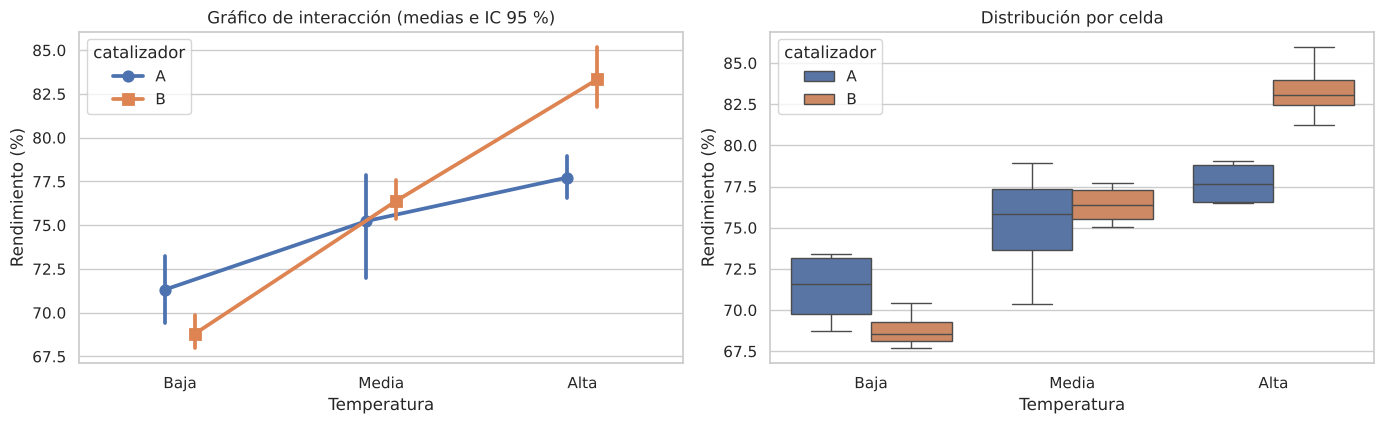

In [38]:
rng_quimica = np.random.default_rng(11)
medias_celda_verdaderas = pd.DataFrame({"A": [70, 75, 77], "B": [69, 76, 85]}, index=["Baja", "Media", "Alta"])
proceso_quimico = pd.DataFrame([
    {"temperatura": temp, "catalizador": cat, "rendimiento": medias_celda_verdaderas.loc[temp, cat] + rng_quimica.normal(0, 2.5)}
    for temp in medias_celda_verdaderas.index for cat in medias_celda_verdaderas.columns for _ in range(4)])
proceso_quimico["temperatura"] = pd.Categorical(proceso_quimico.temperatura, ["Baja", "Media", "Alta"])
print("Medias verdaderas de cada celda (en la práctica son desconocidas):")
display(medias_celda_verdaderas)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.pointplot(data=proceso_quimico, x="temperatura", y="rendimiento", hue="catalizador", errorbar=("ci", 95),
              dodge=0.15, markers=["o", "s"], ax=axes[0])
axes[0].set(title="Gráfico de interacción (medias e IC 95 %)", xlabel="Temperatura", ylabel="Rendimiento (%)")
sns.boxplot(data=proceso_quimico, x="temperatura", y="rendimiento", hue="catalizador", ax=axes[1])
axes[1].set(title="Distribución por celda", xlabel="Temperatura", ylabel="Rendimiento (%)")
plt.tight_layout(); plt.show()

In [39]:
modelo_dos_factores = smf.ols("rendimiento ~ C(temperatura) * C(catalizador)", data=proceso_quimico).fit()
sm.stats.anova_lm(modelo_dos_factores, typ=2)

,sum_sq,df,F,PR(>F)
C(temperatura),439.7458,2.0,48.4179,5.7116e-08
C(catalizador),12.1229,1.0,2.6696,1.1965e-01
C(temperatura):C(catalizador),66.2678,2.0,7.2964,4.7793e-03
Residual,81.7407,18.0,NaN,NaN


**Interpretación.** En el gráfico de interacción las líneas no son paralelas: se cruzan entre las temperaturas baja y media y se separan a temperatura alta. La tabla lo confirma: la interacción es significativa ($p\approx0{,}005$). Cuando hay interacción, **los efectos principales no se interpretan solos**: el efecto principal del catalizador no es significativo porque promedia una ventaja de B a temperatura alta con una ligera desventaja a temperatura baja. Decir "el catalizador no importa" sería un error grave. Lo correcto es analizar los **efectos simples**: comparar los catalizadores dentro de cada temperatura.

In [40]:
efectos_simples = []
for temp, datos_temp in proceso_quimico.groupby("temperatura", observed=True):
    rend_A = datos_temp.loc[datos_temp.catalizador == "A", "rendimiento"]
    rend_B = datos_temp.loc[datos_temp.catalizador == "B", "rendimiento"]
    prueba = stats.ttest_ind(rend_B, rend_A)
    efectos_simples.append({"temperatura": temp, "media A": rend_A.mean(), "media B": rend_B.mean(),
                            "B − A": rend_B.mean() - rend_A.mean(), "p sin ajuste": prueba.pvalue})
efectos_simples = pd.DataFrame(efectos_simples)
efectos_simples["p Holm"] = multipletests(efectos_simples["p sin ajuste"], method="holm")[1]
efectos_simples.round(3)

,temperatura,media A,media B,B − A,p sin ajuste,p Holm
0,Baja,71.318,68.805,-2.513,0.098,0.197
1,Media,75.231,76.392,1.161,0.569,0.569
2,Alta,77.722,83.337,5.615,0.003,0.010


**Conclusión aplicada.** A temperatura alta el catalizador B rinde unos 5,6 puntos porcentuales más que A; a temperaturas baja y media no se detectan diferencias. La recomendación operativa es *temperatura alta con catalizador B*. Si se hubiera ajustado un modelo aditivo (sin interacción), se le habría impuesto a los datos que la ventaja del catalizador es la misma a cualquier temperatura: otra vez, la estructura del modelo condiciona lo que podemos concluir.

### Ausencia de evidencia de interacción no es evidencia de ausencia

> 🔮 **Pregunta de predicción.** Repetimos el mismo proceso (la interacción verdadera **existe**) pero como estudio piloto con sólo 2 corridas por celda y más ruido ($\sigma=4$). ¿Con qué frecuencia la prueba de interacción será significativa?

In [41]:
def p_interaccion_piloto(semilla, replicas=2, sigma=4.0):
    gen = np.random.default_rng(semilla)
    piloto = pd.DataFrame([
        {"temperatura": t, "catalizador": c, "rendimiento": medias_celda_verdaderas.loc[t, c] + gen.normal(0, sigma)}
        for t in medias_celda_verdaderas.index for c in medias_celda_verdaderas.columns for _ in range(replicas)])
    modelo = smf.ols("rendimiento ~ C(temperatura) * C(catalizador)", data=piloto).fit()
    return sm.stats.anova_lm(modelo, typ=2).loc["C(temperatura):C(catalizador)", "PR(>F)"], modelo

p_valores_piloto = np.array([p_interaccion_piloto(s)[0] for s in range(1000)])
print(f"Proporción de pilotos (de 1000) en que la interacción resulta significativa: {np.mean(p_valores_piloto < 0.05):.3f}")

# Un piloto concreto: la interacción no es significativa, pero ¿qué dice el intervalo de confianza?
p_un_piloto, modelo_piloto = p_interaccion_piloto(semilla=12)
# Contraste de interacción: (B − A en temperatura Alta) − (B − A en temperatura Baja)
medias_piloto = modelo_piloto.model.data.frame.groupby(["temperatura", "catalizador"], observed=True).rendimiento.mean()
estimacion = (medias_piloto[("Alta", "B")] - medias_piloto[("Alta", "A")]) - (medias_piloto[("Baja", "B")] - medias_piloto[("Baja", "A")])
error_estandar = np.sqrt(modelo_piloto.mse_resid * 4 / 2)        # cuatro medias de celda, cada una con 2 réplicas
t_crit = stats.t.ppf(0.975, modelo_piloto.df_resid)
print(f"\nPiloto con semilla 12: p de la interacción = {p_un_piloto:.3f}")
print(f"Contraste de interacción estimado = {estimacion:.1f} puntos; IC 95 %: "
      f"[{estimacion - t_crit * error_estandar:.1f}, {estimacion + t_crit * error_estandar:.1f}]   (valor verdadero: 10)")

Proporción de pilotos (de 1000) en que la interacción resulta significativa: 0.193

Piloto con semilla 12: p de la interacción = 0.205
Contraste de interacción estimado = 7.3 puntos; IC 95 %: [-6.0, 20.6]   (valor verdadero: 10)


**Interpretación.** Aunque la interacción verdadera es grande (la ventaja de B cambia en 10 puntos entre temperatura baja y alta), un piloto pequeño la detecta en una minoría de los casos. En el piloto mostrado la prueba no es significativa, pero el intervalo de confianza del contraste de interacción es enorme e incluye tanto el cero como el valor verdadero. Concluir "no hay interacción, los factores actúan de forma aditiva" sería injustificado: la ausencia de evidencia de interacción **no demuestra** que los efectos sean iguales en todos los niveles. Para afirmar igualdad de efectos haría falta un diseño con potencia suficiente y, formalmente, una prueba de equivalencia con un margen de relevancia definido de antemano.

## 6.4 Diseños desbalanceados: sumas de cuadrados de tipo I, II y III

Cuando las celdas tienen distinto número de observaciones, los factores dejan de ser ortogonales y la variabilidad compartida puede asignarse de varias maneras:

| Tipo | Cálculo | Uso |
|---|---|---|
| **I (secuencial)** | Cada término ajustado por los que lo **preceden** en la fórmula | Cuando hay un orden natural; el resultado depende del orden |
| **II** | Cada efecto principal ajustado por los demás efectos principales | Cuando no hay interacción relevante |
| **III** | Cada término ajustado por **todos** los demás | Con interacción; requiere codificación de suma cero |

Ejemplo real con `Cars93`: logaritmo del precio según **origen** (EE. UU. o no) y **tracción** (delantera, trasera, 4×4), con celdas desbalanceadas.

In [42]:
display(pd.crosstab(cars.DriveTrain, cars.Origin, margins=True))
modelo_origen_traccion = smf.ols("log_precio ~ C(Origin) * C(DriveTrain)", data=cars).fit()
modelo_traccion_origen = smf.ols("log_precio ~ C(DriveTrain) * C(Origin)", data=cars).fit()
modelo_suma_cero = smf.ols("log_precio ~ C(Origin, Sum) * C(DriveTrain, Sum)", data=cars).fit()
print("Tipo I, orden Origin → DriveTrain"); print(sm.stats.anova_lm(modelo_origen_traccion, typ=1).round(4))
print("\nTipo I, orden DriveTrain → Origin"); print(sm.stats.anova_lm(modelo_traccion_origen, typ=1).round(4))
print("\nTipo II"); print(sm.stats.anova_lm(modelo_origen_traccion, typ=2).round(4))
print("\nTipo III (contrastes de suma cero)"); print(sm.stats.anova_lm(modelo_suma_cero, typ=3).round(4))

Origin,USA,non-USA,All
DriveTrain,,,
4WD,5,5,10
Front,34,33,67
Rear,9,7,16
All,48,45,93


Tipo I, orden Origin → DriveTrain
                           df   sum_sq  mean_sq        F  PR(>F)
C(Origin)                 1.0   0.0429   0.0429   0.2573  0.6132
C(DriveTrain)             2.0   3.3410   1.6705  10.0267  0.0001
C(Origin):C(DriveTrain)   2.0   1.1414   0.5707   3.4255  0.0370
Residual                 87.0  14.4947   0.1666      NaN     NaN

Tipo I, orden DriveTrain → Origin
                           df   sum_sq  mean_sq       F  PR(>F)
C(DriveTrain)             2.0   3.3036   1.6518  9.9145  0.0001
C(Origin)                 1.0   0.0803   0.0803  0.4817  0.4895
C(DriveTrain):C(Origin)   2.0   1.1414   0.5707  3.4255  0.0370
Residual                 87.0  14.4947   0.1666     NaN     NaN

Tipo II
                          sum_sq    df        F  PR(>F)
C(Origin)                 0.0803   1.0   0.4817  0.4895
C(DriveTrain)             3.3410   2.0  10.0267  0.0001
C(Origin):C(DriveTrain)   1.1414   2.0   3.4255  0.0370
Residual                 14.4947  87.0      NaN     N

**Interpretación.** Con sumas de cuadrados de tipo I, la variabilidad atribuida a `Origin` casi se duplica según vaya antes o después de `DriveTrain`: con diseños desbalanceados, la pregunta "¿cuánto explica el origen?" depende de qué otras variables ya se consideraron. Es la misma lógica de la selección de variables en regresión, donde el aporte de una variable siempre es **parcial**. La interacción es la misma en todos los tipos porque siempre se ajusta por ambos efectos principales.

### Un caso extremo: celdas vacías

In [43]:
pd.crosstab(cars.Type, cars.Origin)

Origin,USA,non-USA
Type,,
Small,7,14
Compact,7,9
Midsize,10,12
Large,11,0
Sporty,8,6
Van,5,4


No hay ningún automóvil grande (*Large*) de origen no estadounidense. Con una celda vacía, el término de interacción $(\alpha\beta)_{\text{Large, non-USA}}$ **no es estimable**: no hay datos que lo informen, y cualquier valor que reporte un programa es consecuencia de la parametrización, no de la evidencia. Sobre los automóviles grandes importados estos datos no permiten decir nada.

## 6.5 Diseño en bloques completos al azar

Cuando existe una fuente de variabilidad conocida pero que no es de interés (operario, lote de materia prima, día, máquina), se **bloquea**: cada bloque recibe todos los tratamientos, en orden aleatorio.

$$
y_{ij}=\mu+\tau_i+\beta_j+\varepsilon_{ij}.
$$

**Ejemplo (datos simulados).** Se comparan 4 métodos de ensamble por su tiempo (min); cada uno de 5 operarios prueba los 4 métodos en orden aleatorio. Los operarios difieren mucho en rapidez.

Sin considerar el bloque (ANOVA de un factor):
             df    sum_sq  mean_sq      F  PR(>F)
C(metodo)   3.0   35.4514  11.8171  0.624  0.6098
Residual   16.0  302.9953  18.9372    NaN     NaN

Con bloque (diseño en bloques completos al azar):
               df    sum_sq  mean_sq         F  PR(>F)
C(metodo)     3.0   35.4514  11.8171   18.2837  0.0001
C(operario)   4.0  295.2395  73.8099  114.2002  0.0000
Residual     12.0    7.7558   0.6463       NaN     NaN


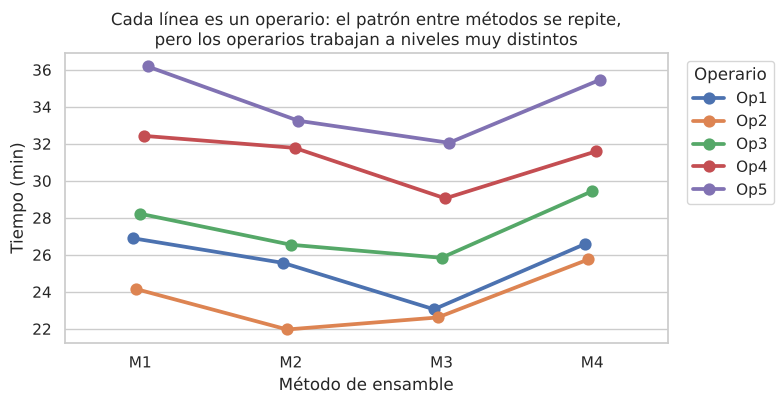

In [44]:
rng_bloques = np.random.default_rng(5)
efecto_metodo_ensamble = {"M1": 0, "M2": -1.5, "M3": -2.0, "M4": 0.5}
efecto_operario = {f"Op{j}": e for j, e in enumerate(rng_bloques.normal(0, 4, 5), start=1)}
ensamble = pd.DataFrame([
    {"metodo": m, "operario": o, "tiempo": 30 + em + eo + rng_bloques.normal(0, 1)}
    for m, em in efecto_metodo_ensamble.items() for o, eo in efecto_operario.items()])

modelo_sin_bloque = smf.ols("tiempo ~ C(metodo)", data=ensamble).fit()
modelo_con_bloque = smf.ols("tiempo ~ C(metodo) + C(operario)", data=ensamble).fit()
print("Sin considerar el bloque (ANOVA de un factor):"); print(sm.stats.anova_lm(modelo_sin_bloque).round(4))
print("\nCon bloque (diseño en bloques completos al azar):"); print(sm.stats.anova_lm(modelo_con_bloque).round(4))

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.pointplot(data=ensamble, x="metodo", y="tiempo", hue="operario", ax=ax, dodge=0.1, errorbar=None)
ax.set(title="Cada línea es un operario: el patrón entre métodos se repite,\npero los operarios trabajan a niveles muy distintos",
       xlabel="Método de ensamble", ylabel="Tiempo (min)")
ax.legend(title="Operario", bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Interpretación.** Sin bloquear, la enorme variabilidad entre operarios queda dentro del error y oculta el efecto del método ($p\approx0{,}6$). Al incluir el bloque, esa variabilidad se separa, el cuadrado medio del error cae de cerca de 19 a menos de 1 y el efecto del método se vuelve claro. Bloquear equivale a comparar a cada operario consigo mismo. El modelo en bloques supone que no hay interacción entre bloque y tratamiento (el patrón entre métodos es el mismo para todos los operarios), lo que el gráfico respalda razonablemente.

## 6.6 ANOVA de medidas repetidas

En un diseño de **medidas repetidas** la misma unidad se mide en todas las condiciones (por ejemplo, el mismo trabajador usando tres herramientas). Se parece al diseño en bloques, con dos diferencias importantes: las condiciones se aplican **sucesivamente** a la misma unidad, lo que puede generar efectos de orden, aprendizaje o fatiga (por eso se aleatoriza o contrabalancea el orden), y las mediciones de una misma unidad están **correlacionadas**.

Por esa correlación, el ANOVA de medidas repetidas requiere un supuesto adicional, la **esfericidad**: las varianzas de las diferencias entre cada par de condiciones deben ser iguales. Se evalúa con la prueba de Mauchly y, si no se cumple, se corrigen los grados de libertad multiplicándolos por un factor $\varepsilon$ (Greenhouse-Geisser), que vale 1 bajo esfericidad perfecta y $1/(k-1)$ en el peor caso. La alternativa no paramétrica es la prueba de **Friedman**.

**Ejemplo (datos simulados).** Doce operarios ensamblan una pieza con tres herramientas (manual, neumática, eléctrica), en orden aleatorio, y se registra el tiempo (s).

In [45]:
rng_rm = np.random.default_rng(31)
efecto_herramienta = {"manual": 0, "neumatica": -6, "electrica": -8}
n_operarios = 12
habilidad = rng_rm.normal(0, 10, n_operarios)                      # cada operario tiene su propio nivel
medidas_repetidas = pd.DataFrame([
    {"operario": f"T{o+1:02d}", "herramienta": h, "tiempo_s": 120 + habilidad[o] + eh + rng_rm.normal(0, 4)}
    for o in range(n_operarios) for h, eh in efecto_herramienta.items()])

anova_rm = AnovaRM(medidas_repetidas, depvar="tiempo_s", subject="operario", within=["herramienta"]).fit()
print(anova_rm)

# Comparación: el mismo análisis ignorando que las mediciones son del mismo operario (incorrecto)
print("ANOVA de un factor que ignora la estructura de medidas repetidas (incorrecto):")
print(sm.stats.anova_lm(smf.ols("tiempo_s ~ C(herramienta)", data=medidas_repetidas).fit()).round(4))

                  Anova
            F Value Num DF  Den DF Pr > F
-----------------------------------------
herramienta 19.8975 2.0000 22.0000 0.0000

ANOVA de un factor que ignora la estructura de medidas repetidas (incorrecto):
                  df     sum_sq   mean_sq       F  PR(>F)
C(herramienta)   2.0   319.2285  159.6143  1.6458  0.2083
Residual        33.0  3200.4208   96.9824     NaN     NaN


In [46]:
def esfericidad(datos, sujeto, condicion, respuesta):
    '''Prueba de Mauchly y épsilon de Greenhouse-Geisser para un factor intra-sujeto.'''
    matriz = datos.pivot(index=sujeto, columns=condicion, values=respuesta)
    n, k = matriz.shape
    S = np.cov(matriz.values, rowvar=False)
    # Contrastes ortonormales (k-1 columnas ortogonales al vector de unos)
    contrastes = np.linalg.qr(np.column_stack([np.ones(k), np.eye(k)[:, : k - 1]]))[0][:, 1:]
    S_c = contrastes.T @ S @ contrastes
    p = k - 1
    W = np.linalg.det(S_c) / (np.trace(S_c) / p) ** p
    f = 1 - (2 * p ** 2 + p + 2) / (6 * p * (n - 1))
    chi2 = -(n - 1) * f * np.log(W)
    gl = p * (p + 1) / 2 - 1
    epsilon_gg = np.trace(S_c) ** 2 / (p * np.trace(S_c @ S_c))
    return {"W de Mauchly": W, "chi2": chi2, "gl": gl, "p Mauchly": stats.chi2.sf(chi2, gl),
            "épsilon Greenhouse-Geisser": epsilon_gg}

resultado_esfericidad = esfericidad(medidas_repetidas, "operario", "herramienta", "tiempo_s")
display(pd.Series(resultado_esfericidad).round(4))

F_rm = anova_rm.anova_table["F Value"].iloc[0]
gl_num_rm, gl_den_rm = anova_rm.anova_table["Num DF"].iloc[0], anova_rm.anova_table["Den DF"].iloc[0]
eps = resultado_esfericidad["épsilon Greenhouse-Geisser"]
print(f"p sin corrección = {stats.f.sf(F_rm, gl_num_rm, gl_den_rm):.2e}   |   "
      f"p con corrección GG (gl {eps*gl_num_rm:.2f}, {eps*gl_den_rm:.2f}) = {stats.f.sf(F_rm, eps*gl_num_rm, eps*gl_den_rm):.2e}")

friedman = stats.friedmanchisquare(*[g.sort_values("operario").tiempo_s.values
                                     for _, g in medidas_repetidas.groupby("herramienta")])
print(f"Friedman (alternativa no paramétrica): chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2e}")

W de Mauchly                  0.9987
chi2                          0.0126
gl                            2.0000
p Mauchly                     0.9937
épsilon Greenhouse-Geisser    0.9987
dtype: float64

p sin corrección = 1.16e-05   |   p con corrección GG (gl 2.00, 21.97) = 1.18e-05
Friedman (alternativa no paramétrica): chi2 = 16.17, p = 3.09e-04


**Interpretación.** El ANOVA de medidas repetidas detecta con claridad el efecto de la herramienta. El ANOVA de un factor que ignora la estructura de los datos, en cambio, mezcla las diferencias de habilidad entre operarios con el error y pierde casi toda la sensibilidad, además de violar el supuesto de independencia. La prueba de Mauchly no aporta evidencia contra la esfericidad y el épsilon de Greenhouse-Geisser está cerca de 1, por lo que la corrección apenas cambia el resultado. Las comparaciones por pares en medidas repetidas se hacen con pruebas $t$ **pareadas** y ajuste de Holm; Tukey HSD no es adecuado porque supone grupos independientes.

## 6.7 ANCOVA: comparar grupos ajustando por una covariable

> **Pregunta orientadora.** ¿Los automóviles medianos son más caros por ser medianos o porque tienden a tener motores más potentes?

El análisis de covarianza agrega una variable cuantitativa $x$ al modelo:

$$
y_{ij}=\mu+\tau_i+\gamma\,(x_{ij}-\bar x)+\varepsilon_{ij}.
$$

Supone, además de lo habitual, **pendientes homogéneas**: la relación entre $x$ y $y$ es la misma en todos los grupos (rectas paralelas). Este supuesto se evalúa con la interacción factor × covariable.

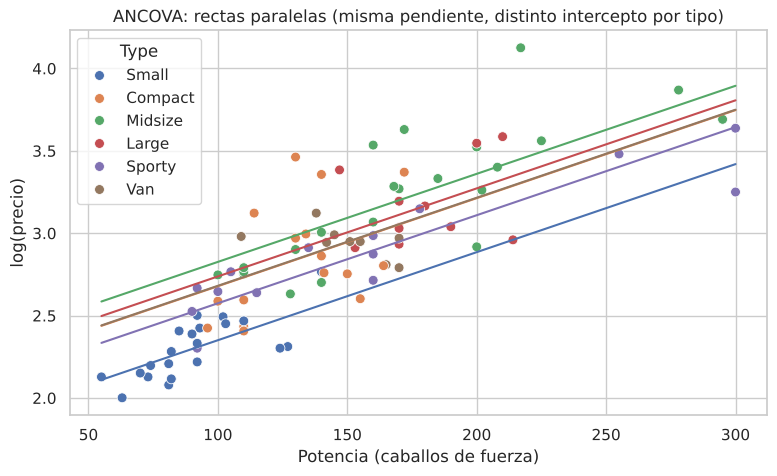

1) Pendientes homogéneas: ¿es significativa la interacción Tipo × Potencia?


                    sum_sq    df        F  PR(>F)
C(Type)             1.8820   5.0   7.9583  0.0000
Horsepower          4.4056   1.0  93.1469  0.0000
C(Type):Horsepower  0.3719   5.0   1.5725  0.1772
Residual            3.8311  81.0      NaN     NaN

2) ANCOVA (sumas de cuadrados tipo II)
            sum_sq    df        F  PR(>F)
C(Type)     1.8820   5.0   7.7019     0.0
Horsepower  4.4056   1.0  90.1464     0.0
Residual    4.2029  86.0      NaN     NaN

η² del tipo sin ajustar: 0.547   |   η² parcial del tipo ajustando por potencia: 0.309


In [47]:
modelo_ancova = smf.ols("log_precio ~ C(Type) + Horsepower", data=cars).fit()
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=cars, x="Horsepower", y="log_precio", hue="Type", ax=ax, s=50)
potencias = np.linspace(cars.Horsepower.min(), cars.Horsepower.max(), 50)
for posicion, tipo in enumerate(ORDEN_TIPOS):
    ax.plot(potencias, modelo_ancova.predict(pd.DataFrame({"Type": tipo, "Horsepower": potencias})), color=f"C{posicion}")
ax.set(title="ANCOVA: rectas paralelas (misma pendiente, distinto intercepto por tipo)",
       xlabel="Potencia (caballos de fuerza)", ylabel="log(precio)")
plt.show()

print("1) Pendientes homogéneas: ¿es significativa la interacción Tipo × Potencia?")
print(sm.stats.anova_lm(smf.ols("log_precio ~ C(Type) * Horsepower", data=cars).fit(), typ=2).round(4))
tabla_ancova = sm.stats.anova_lm(modelo_ancova, typ=2)
print("\n2) ANCOVA (sumas de cuadrados tipo II)"); print(tabla_ancova.round(4))
eta2_parcial_tipo = tabla_ancova.sum_sq.iloc[0] / (tabla_ancova.sum_sq.iloc[0] + tabla_ancova.sum_sq.iloc[-1])
print(f"\nη² del tipo sin ajustar: {tamanos_del_efecto(tabla_cars_log)['eta²']:.3f}   |   "
      f"η² parcial del tipo ajustando por potencia: {eta2_parcial_tipo:.3f}")

**Interpretación.** La interacción tipo × potencia no es significativa, de modo que el supuesto de pendientes homogéneas es razonable con estos datos (con la advertencia de la sección 6.3: eso no prueba que las pendientes sean idénticas). La potencia del motor se asocia fuertemente con el precio. Después de ajustar por ella, el tipo sigue asociado al precio, pero con un efecto menor: parte de lo que atribuíamos al "tipo" corresponde a diferencias de potencia. Como los datos son observacionales, el ajuste no convierte la asociación en causal: puede haber otras variables (marca, equipamiento) que expliquen las diferencias restantes.

## 6.8 Efectos aleatorios (introducción)

Si los niveles del factor son una **muestra** de una población de niveles posibles (por ejemplo, 15 lotes de materia prima elegidos al azar), no interesa cada lote en particular sino **cuánta variabilidad** introducen los lotes:

$$
y_{ij}=\mu+a_i+\varepsilon_{ij},\qquad a_i\sim N(0,\sigma_a^2),\quad \varepsilon_{ij}\sim N(0,\sigma^2).
$$

La pregunta pasa a ser si $\sigma_a^2>0$, y la **correlación intraclase** $\rho=\sigma_a^2/(\sigma_a^2+\sigma^2)$ mide qué proporción de la variabilidad se debe a los lotes.

In [48]:
rng_lotes = np.random.default_rng(4)
sigma_lote, sigma_error = 2.0, 1.5                          # verdad: ICC = 4 / (4 + 2,25) = 0,64
lotes = pd.DataFrame([{"lote": f"L{i:02d}", "pureza": 95 + efecto + rng_lotes.normal(0, sigma_error)}
                      for i, efecto in enumerate(rng_lotes.normal(0, sigma_lote, 15)) for _ in range(5)])
modelo_mixto = smf.mixedlm("pureza ~ 1", data=lotes, groups="lote").fit(reml=True)
varianza_lote, varianza_error = float(modelo_mixto.cov_re.iloc[0, 0]), modelo_mixto.scale
print(modelo_mixto.summary())
print(f"σ²_lote estimada = {varianza_lote:.2f} (verdadera {sigma_lote**2:.2f});  "
      f"σ²_error estimada = {varianza_error:.2f} (verdadera {sigma_error**2:.2f})")
print(f"Correlación intraclase estimada = {varianza_lote / (varianza_lote + varianza_error):.2f} "
      f"(verdadera {sigma_lote**2 / (sigma_lote**2 + sigma_error**2):.2f})")

         Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: pureza   
No. Observations: 75      Method:             REML     
No. Groups:       15      Scale:              2.6792   
Min. group size:  5       Log-Likelihood:     -158.2442
Max. group size:  5       Converged:          Yes      
Mean group size:  5.0                                  
-------------------------------------------------------
            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------
Intercept   94.767    0.537 176.471 0.000 93.715 95.820
lote Var     3.790    1.109                            

σ²_lote estimada = 3.79 (verdadera 4.00);  σ²_error estimada = 2.68 (verdadera 2.25)
Correlación intraclase estimada = 0.59 (verdadera 0.64)


**Interpretación.** $\sigma_a^2$ se estima a partir del número de **lotes** (15), no del número total de mediciones (75); por eso su estimación es bastante imprecisa. ✏️ Cambie la semilla de `rng_lotes` y observe cuánto varía. Para generalizar a "todos los lotes posibles" se necesitan muchos lotes, no muchas mediciones por lote.

## 6.9 El mapa: todo es un modelo lineal

```
                       MODELO LINEAL GENERAL   y = Xβ + ε
                                   │
     ┌─────────────┬───────────────┼───────────────┬──────────────────────────┐
  Regresión      ANOVA          ANCOVA      Modelos mixtos              Extensiones
 (X continuas) (X categóricas)  (ambas)   (efectos aleatorios,      ├ MANOVA (varias respuestas)
                ├ 1 factor                  medidas repetidas)      └ Modelos lineales generalizados
                ├ 2 o más factores                                    (respuestas binarias, conteos)
                └ bloques
```

Todos comparten la misma lógica: descomponer la variabilidad, comparar modelos anidados mediante pruebas $F$ y verificar que la estructura supuesta sea compatible con los datos. La prueba $F$ parcial que usan los métodos de selección de variables (*forward*, *backward*, *stepwise*) es la misma prueba $F$ del ANOVA.

---
# Unidad 7. Profundización matemática

Esta unidad formaliza lo que en las anteriores se trató de manera intuitiva. Es recomendable para quien desee comprender por qué los programas reportan coeficientes distintos para un mismo ANOVA y qué cantidades tienen significado propio.

## 7.1 ANOVA como regresión lineal

El modelo de medias de celda se escribe matricialmente como $\mathbf y=\mathbf X\boldsymbol\beta+\boldsymbol\varepsilon$, donde $\mathbf X$ tiene una columna indicadora (0/1) por grupo y $\boldsymbol\beta=(\mu_1,\dots,\mu_k)^\top$. El estimador de mínimos cuadrados $\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$ es simplemente el vector de medias de los grupos, y la prueba $F$ del ANOVA es la prueba $F$ de la regresión que compara este modelo con el modelo que sólo tiene intercepto.

## 7.2 Identificabilidad: un problema de estructura

El modelo de efectos $y_{ij}=\mu+\tau_i+\varepsilon_{ij}$ tiene $k+1$ parámetros, pero los datos sólo informan sobre $k$ medias. Hay infinitas combinaciones de parámetros que producen las mismas medias; por ejemplo,

$$
\mu=20,\ \tau=(-3,0,3)\qquad\text{y}\qquad\mu=25,\ \tau=(-8,-5,-2)
$$

dan ambas $\mu_i=(17,20,23)$. Se dice que los parámetros **no son identificables**. En términos matriciales, la matriz de diseño **no tiene rango completo** y $\mathbf X^\top\mathbf X$ no es invertible.

In [49]:
grupo_ejemplo = np.repeat(["A", "B", "C"], 2)
X_sobreparametrizada = pd.DataFrame({
    "mu": 1,
    "tau_A": (grupo_ejemplo == "A").astype(int),
    "tau_B": (grupo_ejemplo == "B").astype(int),
    "tau_C": (grupo_ejemplo == "C").astype(int)}, index=grupo_ejemplo)
display(X_sobreparametrizada)
print(f"Columnas: {X_sobreparametrizada.shape[1]}   |   Rango: {np.linalg.matrix_rank(X_sobreparametrizada)}")
print("La columna 'mu' es la suma de las otras tres; por eso X'X es singular.")

,mu,tau_A,tau_B,tau_C
A,1,1,0,0
A,1,1,0,0
B,1,0,1,0
B,1,0,1,0
C,1,0,0,1
C,1,0,0,1


Columnas: 4   |   Rango: 3
La columna 'mu' es la suma de las otras tres; por eso X'X es singular.


## 7.3 Restricciones y parametrizaciones

Para obtener una solución única se impone **una** restricción lineal sobre los $\tau_i$. Las dos más usadas son:

| Restricción | Codificación en `statsmodels` | Significado del intercepto | Significado de cada coeficiente |
|---|---|---|---|
| **Celda de referencia**: $\tau_1=0$ | `C(Type)` (tratamiento, por defecto) | Media del grupo de referencia | Diferencia entre la media del grupo y la del grupo de referencia |
| **Suma cero**: $\sum_i\tau_i=0$ | `C(Type, Sum)` | Promedio **no ponderado** de las $k$ medias de grupo | Desviación de la media del grupo respecto a ese promedio (el último grupo se obtiene por diferencia) |

Conviene distinguir tres ideas que suelen confundirse:

- **Identificabilidad** es una propiedad del modelo: si distintos valores de los parámetros producen la misma distribución de los datos, los parámetros no son identificables.
- Una **restricción** es una convención que elige una de las infinitas soluciones; no se deduce de los datos ni se puede contrastar con ellos.
- Una **función estimable** es una combinación lineal de parámetros cuyo valor es el mismo bajo **cualquier** restricción; por eso tiene significado propio.

In [50]:
modelo_referencia = smf.ols("log_precio ~ C(Type)", data=cars).fit()          # τ_Small = 0
modelo_suma_cero_tipo = smf.ols("log_precio ~ C(Type, Sum)", data=cars).fit()  # Σ τ_i = 0
parametros = pd.concat([modelo_referencia.params.rename("referencia (Small = 0)").reset_index(drop=True),
                        modelo_suma_cero_tipo.params.rename("suma cero").reset_index(drop=True)], axis=1)
parametros.index = ["Intercepto", "coef. 2", "coef. 3", "coef. 4", "coef. 5", "coef. 6"]
print("Los coeficientes cambian con la restricción:")
display(parametros.round(4))

Los coeficientes cambian con la restricción:


,referencia (Small = 0),suma cero
Intercepto,2.3029,2.8947
coef. 2,0.5414,-0.5919
coef. 3,0.9139,-0.0504
coef. 4,0.8597,0.3220
coef. 5,0.5936,0.2679
coef. 6,0.6425,0.0018


In [51]:
nuevos_tipos = pd.DataFrame({"Type": pd.Categorical(ORDEN_TIPOS, categories=ORDEN_TIPOS)})
cantidades_estimables = pd.DataFrame({
    "media muestral": cars.groupby("Type", observed=True).log_precio.mean().values,
    "media ajustada (referencia)": modelo_referencia.predict(nuevos_tipos).values,
    "media ajustada (suma cero)": modelo_suma_cero_tipo.predict(nuevos_tipos).values,
}, index=ORDEN_TIPOS)
print("…pero las medias de grupo (funciones estimables) son idénticas:")
display(cantidades_estimables.round(4))
print(f"SC residual: {modelo_referencia.ssr:.6f} vs {modelo_suma_cero_tipo.ssr:.6f}   |   "
      f"F global: {modelo_referencia.fvalue:.4f} vs {modelo_suma_cero_tipo.fvalue:.4f}")

…pero las medias de grupo (funciones estimables) son idénticas:


,media muestral,media ajustada (referencia),media ajustada (suma cero)
Small,2.3029,2.3029,2.3029
Compact,2.8443,2.8443,2.8443
Midsize,3.2168,3.2168,3.2168
Large,3.1626,3.1626,3.1626
Sporty,2.8965,2.8965,2.8965
Van,2.9454,2.9454,2.9454


SC residual: 8.608482 vs 8.608482   |   F global: 21.0444 vs 21.0444


**Interpretación.** Los coeficientes individuales dependen de la convención elegida, mientras que las medias de grupo, sus diferencias, cualquier contraste $\sum c_i\mu_i$ con $\sum c_i=0$, la suma de cuadrados residual y la prueba $F$ son idénticos. Formalmente, $\mathbf c^\top\boldsymbol\beta$ es estimable si y sólo si $\mathbf c^\top$ es una combinación lineal de las filas de $\mathbf X$. En la práctica, **reportar medias, diferencias y contrastes**, y no un "efecto $\tau_i$" aislado cuyo valor depende de una convención, es la forma rigurosa de generalizar.

## 7.4 Distribución muestral de los estimadores y cuadrados medios esperados

> 🔮 **Pregunta de predicción.** Si simulamos muchas veces un experimento con $\mu=20$, $\tau=(-3,0,3)$, $\sigma=2$ y 8 observaciones por grupo, ¿alrededor de qué valores se centrarán los efectos estimados y el $CM_E$?

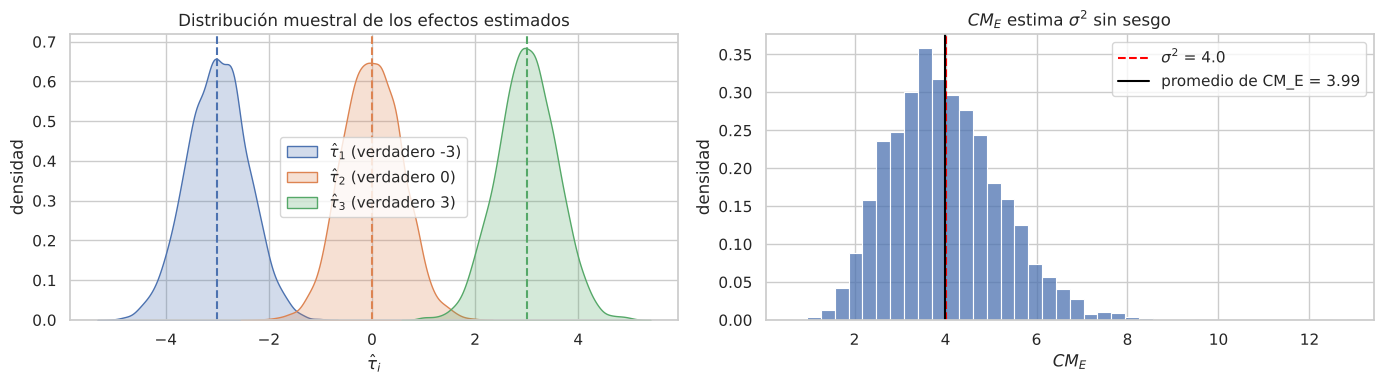

E(CM_Tr) teórico = σ² + n Σ τ² / (k−1) = 76.0;   promedio simulado = 76.1


In [52]:
mu_verdadera, tau_verdaderos, sigma_v, n_por_grupo = 20, np.array([-3, 0, 3]), 2.0, 8
repeticiones = 4000
gen_estimadores = np.random.default_rng(SEMILLA)
y_sim = mu_verdadera + tau_verdaderos[None, :, None] + gen_estimadores.normal(0, sigma_v, size=(repeticiones, 3, n_por_grupo))
medias_sim = y_sim.mean(axis=2)
tau_estimados = medias_sim - medias_sim.mean(axis=1, keepdims=True)              # restricción de suma cero
cm_error_sim = ((y_sim - medias_sim[:, :, None]) ** 2).sum(axis=(1, 2)) / (3 * (n_por_grupo - 1))
cm_trat_sim = n_por_grupo * ((medias_sim - medias_sim.mean(axis=1, keepdims=True)) ** 2).sum(axis=1) / 2

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for i in range(3):
    sns.kdeplot(tau_estimados[:, i], ax=axes[0], fill=True, label=fr"$\hat\tau_{i+1}$ (verdadero {tau_verdaderos[i]})")
    axes[0].axvline(tau_verdaderos[i], color=f"C{i}", ls="--")
axes[0].set(title="Distribución muestral de los efectos estimados", xlabel=r"$\hat\tau_i$", ylabel="densidad"); axes[0].legend()
sns.histplot(cm_error_sim, ax=axes[1], stat="density", bins=40)
axes[1].axvline(sigma_v ** 2, color="red", ls="--", label=fr"$\sigma^2$ = {sigma_v**2}")
axes[1].axvline(cm_error_sim.mean(), color="black", label=f"promedio de CM_E = {cm_error_sim.mean():.2f}")
axes[1].set(title=r"$CM_E$ estima $\sigma^2$ sin sesgo", xlabel=r"$CM_E$", ylabel="densidad"); axes[1].legend()
plt.tight_layout(); plt.show()

esperado_cm_trat = sigma_v ** 2 + n_por_grupo * np.sum(tau_verdaderos ** 2) / 2
print(f"E(CM_Tr) teórico = σ² + n Σ τ² / (k−1) = {esperado_cm_trat:.1f};   promedio simulado = {cm_trat_sim.mean():.1f}")

**Interpretación.** Cuando la estructura del modelo es correcta, los estimadores se centran en los valores verdaderos (son **insesgados**), $CM_E$ estima $\sigma^2$ y $CM_{Tr}$ estima $\sigma^2+n\sum\tau_i^2/(k-1)$, como establece la teoría. Esa es la base de la prueba $F$ y de toda generalización de la muestra a la población. La Unidad 4 mostró qué ocurre cuando la estructura no se cumple.

---
# Unidad 8. Taller práctico de aplicación

## 8.1 Problema: resistencia de lámina de cuatro proveedores

> 🧪 **Datos simulados.** Los datos se generan en la celda siguiente con una semilla fija; no conocerá los parámetros con que se generaron hasta revisar el anexo docente.

El área de compras de una empresa metalmecánica evalúa a **cuatro proveedores** de lámina de acero. De los despachos del último trimestre se tomaron al azar probetas de cada proveedor y se midió su **resistencia a la tensión** (MPa) en el laboratorio de calidad. No todos los proveedores entregaron la misma cantidad de despachos, por lo que el número de probetas difiere. La especificación técnica exige una resistencia media de al menos 400 MPa, y el área de compras quiere saber si los proveedores difieren y, en caso afirmativo, cuáles.

**Tareas** (desarrolle cada una en celdas nuevas, con código **e** interpretación escrita):

1. Identifique la variable respuesta, el factor, los niveles, la unidad experimental y si el estudio es experimental u observacional. ¿Qué alcance tendrán las conclusiones?
2. Formule las hipótesis del ANOVA.
3. Realice la exploración descriptiva: tabla de estadísticos por proveedor y al menos dos gráficos adecuados.
4. Ajuste el ANOVA de un factor y construya la tabla.
5. Diagnostique los supuestos con gráficos y pruebas. Con base en el diagnóstico y en el diseño, decida entre ANOVA clásico y Welch, y justifique.
6. Si corresponde, realice las comparaciones múltiples con el procedimiento adecuado (Tukey o Games-Howell) y preséntelas gráficamente.
7. Calcule $\eta^2$ y $\omega^2$ e interprételos en el contexto.
8. Redacte un párrafo de conclusiones para el área de compras (máximo 150 palabras) que incluya los resultados estadísticos y su significado práctico respecto a la especificación de 400 MPa.

**Verificación de sus respuestas:** el anexo docente contiene la solución completa. Antes de consultarlo, compruebe que (a) la suma de cuadrados entre grupos más la del error es igual a la total; (b) los grados de libertad del error son $N-k$; (c) su decisión entre clásico y Welch es coherente con el cociente de desviaciones estándar y con el balance del diseño.

In [53]:
# Datos del taller (simulados). No modifique esta celda.
rng_taller = np.random.default_rng(2029)
_parametros_taller = {"Proveedor_1": (412, 8, 12), "Proveedor_2": (405, 9, 15),
                      "Proveedor_3": (398, 20, 7), "Proveedor_4": (414, 7, 10)}   # (media, DE, n): ¡no mire hasta resolver!
taller = pd.DataFrame([{"proveedor": prov, "resistencia_MPa": round(rng_taller.normal(m, s), 1)}
                       for prov, (m, s, n) in _parametros_taller.items() for _ in range(n)])
taller.head()

,proveedor,resistencia_MPa
0,Proveedor_1,410.0
1,Proveedor_1,417.1
2,Proveedor_1,406.0
3,Proveedor_1,423.6
4,Proveedor_1,412.2


In [54]:
# ✏️ Desarrolle aquí su análisis (agregue tantas celdas como necesite).

## 8.2 Ejercicios por niveles

### Nivel básico: identificación

**B1.** Para cada situación, identifique variable respuesta, factor y niveles, unidad experimental y si el estudio es experimental u observacional: (a) se comparan los puntajes de una prueba estandarizada entre cinco colegios de una ciudad; (b) se asignan al azar 40 parcelas a cuatro dosis de fertilizante y se mide el rendimiento; (c) en una línea de envasado se toman 10 botellas de cada uno de 3 turnos y se mide el volumen.

**B2.** En la situación (b), un investigador toma 5 plantas de cada parcela y analiza las 200 plantas como observaciones independientes. ¿Qué error comete? ¿Cuántos grados de libertad del error tendría el análisis correcto?

**B3.** Escriba $H_0$ y $H_1$ para la situación (a). Explique por qué rechazar $H_0$ no implica que los cinco colegios sean distintos entre sí.

### Nivel intermedio: cálculo e interpretación

**I1.** Con `Cars93`, analice si el consumo en ciudad (`MPG_city`) difiere según el tipo de tracción (`DriveTrain`). Construya la tabla ANOVA **a mano** con `pandas` (como en la sección 2.5) y verifíquela con `statsmodels`.

**I2.** Complete la tabla ANOVA siguiente y decida con $\alpha=0{,}05$: $k=4$ grupos, $n_i=6$ por grupo, $SC_{Tr}=84$, $SC_T=204$. Calcule además $\eta^2$ y $\omega^2$.

**I3.** Interprete en palabras un valor $p=0{,}03$ en un ANOVA. Escriba también dos interpretaciones **incorrectas** frecuentes.

### Nivel aplicado: supuestos y alternativas

**A1.** Diagnostique los supuestos del modelo de I1. ¿Conviene transformar la respuesta? ¿Es preferible Welch? Justifique con el diseño (tamaños de grupo) y con los gráficos.

**A2.** Modifique la Simulación 3 (sección 4.6) para generar los datos con distribución exponencial en lugar de normal (`gen.exponential`), con medias iguales y $n=5$ por grupo; luego con $n=30$. ¿Se mantiene el 5 % de error de tipo I? Relacione su resultado con el teorema central del límite.

**A3.** Un colega obtiene un Kruskal-Wallis significativo con grupos de dispersión muy distinta y concluye que "las medianas difieren". Explique por qué esa conclusión no está justificada.

### Nivel avanzado: interacciones, contrastes y parametrizaciones

**V1.** En el experimento químico (sección 6.3), cambie las medias verdaderas para que **no** haya interacción (líneas paralelas). Ajuste el modelo y explique por qué un $p$ grande para la interacción no basta para afirmar que los efectos son aditivos.

**V2.** En el caso A (producción), formule y estime el contraste que compara el método B con el método C, y otro que compara el método actual con el promedio de los nuevos. Ajuste ambos valores $p$ con Holm.

**V3.** Ajuste el modelo `log_precio ~ C(Type, Treatment(reference="Midsize"))`. ¿Qué significan ahora el intercepto y los coeficientes? Demuestre numéricamente que la diferencia *Large − Small* es la misma que con la codificación por defecto.

---
# Síntesis

| Unidad | Idea central |
|---|---|
| 1. Qué es ANOVA | Comparar varias medias con **una** prueba global evita inflar el error por familia; la evidencia surge de comparar la variabilidad entre grupos con la variabilidad dentro de ellos. El diseño (unidad experimental, aleatorización) define el alcance de las conclusiones. |
| 2. Fundamento | $SC_T=SC_{Tr}+SC_E$, con $N-1=(k-1)+(N-k)$ grados de libertad; $F=CM_{Tr}/CM_E\sim F_{k-1,N-k}$ bajo $H_0$ y los supuestos. |
| 3. Python | `smf.ols("y ~ C(factor)")` + `anova_lm`; una conclusión reporta $F$, gl, $p$, tamaño del efecto y alcance. |
| 4. Diagnóstico | Independencia por diseño; normalidad y homocedasticidad con gráficos de residuos, apoyados por pruebas cuyas limitaciones se conocen. Con diseño desbalanceado y varianzas distintas, la $F$ clásica falla y Welch no. |
| 5. Comparaciones y efecto | Tukey HSD con varianza común; Games-Howell con varianzas distintas; contrastes para preguntas planeadas; $\omega^2$ corrige el sesgo de $\eta^2$; la importancia práctica se juzga en unidades del problema. |
| 6. Extensiones | Interacción (los efectos principales no se interpretan solos), tipos de SC en diseños desbalanceados, bloques, medidas repetidas (esfericidad), ANCOVA (pendientes homogéneas), efectos aleatorios. |
| 7. Profundización | Los $\tau_i$ requieren una restricción; las medias y los contrastes son funciones estimables; el ANOVA es una regresión con predictores categóricos. |

**Sobre la competencia.** Toda conclusión de un ANOVA es condicional a su estructura: "el método reduce el tiempo" significa, en rigor, *si las observaciones son independientes, aproximadamente normales y con varianza común, entonces…*. Las simulaciones mostraron el costo de ignorar esa condición. Flexibilizar la estructura (transformar, usar Welch o Games-Howell, añadir bloques o covariables) no es hacer trampa: es adaptar el modelo a la realidad. Y el diseño marca el alcance: con asignación aleatoria se puede hablar de efectos; con datos observacionales, de asociaciones; con celdas vacías, no se puede hablar.

## Glosario

- **Factor / niveles:** variable categórica que define los grupos y sus categorías.
- **Unidad experimental:** entidad que recibe el tratamiento de manera independiente mediante la aleatorización.
- **Pseudorreplicación:** tratar como independientes mediciones repetidas de una misma unidad experimental.
- **$SC_{Tr}$, $SC_E$, $SC_T$:** sumas de cuadrados entre grupos, dentro de los grupos y total.
- **Cuadrado medio:** suma de cuadrados dividida por sus grados de libertad.
- **Error por familia (FWER):** probabilidad de al menos un falso positivo en un conjunto de pruebas.
- **Prueba liberal / conservadora:** rechaza una $H_0$ verdadera más / menos veces que el nivel nominal $\alpha$.
- **Función estimable:** combinación de parámetros cuyo valor no depende de la restricción de identificación.
- **Interacción:** situación en que el efecto de un factor depende del nivel de otro.
- **Esfericidad:** igualdad de las varianzas de las diferencias entre condiciones en un diseño de medidas repetidas.
- **Covariable:** variable cuantitativa que se ajusta para comparar grupos en condiciones equivalentes.

## Referencias

- Cohen, J. (1988). *Statistical Power Analysis for the Behavioral Sciences* (2.ª ed.). Lawrence Erlbaum.
- Delacre, M., Leys, C., Mora, Y. L. y Lakens, D. (2019). Taking parametric assumptions seriously: Arguments for the use of Welch's F-test instead of the classical F-test in one-way ANOVA. *International Review of Social Psychology*, 32(1), 13.
- Games, P. A. y Howell, J. F. (1976). Pairwise multiple comparison procedures with unequal n's and/or variances: A Monte Carlo study. *Journal of Educational Statistics*, 1(2), 113–125.
- Hurlbert, S. H. (1984). Pseudoreplication and the design of ecological field experiments. *Ecological Monographs*, 54(2), 187–211.
- Kutner, M., Nachtsheim, C., Neter, J. y Li, W. (2005). *Applied Linear Statistical Models* (5.ª ed.), partes III y IV. McGraw-Hill.
- Lock, R. H. (1993). 1993 New Car Data. *Journal of Statistics Education*, 1(1).
- Montgomery, D. C. (2017). *Design and Analysis of Experiments* (9.ª ed.), caps. 3 a 5 y 14. Wiley.
- Olejnik, S. y Algina, J. (2003). Generalized eta and omega squared statistics. *Psychological Methods*, 8(4), 434–447.
- Searle, S. R. y Gruber, M. H. J. (2016). *Linear Models* (2.ª ed.), cap. 5. Wiley.
- Welch, B. L. (1951). On the comparison of several mean values: An alternative approach. *Biometrika*, 38(3/4), 330–336.
- Amat Rodrigo, J. (2016). *ANOVA: análisis de varianza para comparar múltiples medias*. Ciencia de Datos. https://cienciadedatos.net/documentos/19_anova (material complementario consultado; ver informe de cambios).

---
---
# 📕 Anexo para uso docente: solucionario y pistas

> Esta sección está separada intencionalmente del cuerpo del cuadernillo. Si se distribuye a los estudiantes para trabajo autónomo, puede eliminarse o entregarse después de la actividad.

## Pistas de las reflexiones

- **1.1** Respuesta: tiempo de espera; factor: sede (3 niveles); unidad de observación: cada atención registrada. Es observacional: las sedes atienden poblaciones, horarios y casos distintos, de modo que no puede hablarse de causalidad.
- **1.2** Estandarizar materia prima y operarios, bloquear por turno u operario, mejorar la precisión de la medición.
- **2.1** Cambian $SC_E$ (y $SC_T$) y también la media de A, por lo que cambia $SC_{Tr}$. Con 19 la media de A pasa a 11,5, el grupo se dispersa mucho más y $F$ disminuye.
- **3.1** Usar "se asocia", "difiere en promedio"; evitar "el tipo provoca/causa/determina el precio".
- **4.1** Un $p>0{,}05$ indica falta de evidencia contra la normalidad, no que la distribución sea normal; con $n$ moderado la prueba tiene potencia limitada. Reformulación: "no se observan desviaciones relevantes de la normalidad en el gráfico Q-Q y la prueba de Shapiro-Wilk no las detecta".
- **5.1** `potencia_teorica.solve_power(effect_size=np.std([40, 41.5, 43]) / 3, alpha=0.05, power=0.8, k_groups=3) / 3` da alrededor de 20 órdenes por método (21 al redondear hacia arriba).

## Solución del taller (8.1)

Parámetros con que se generaron los datos (media, DE, n): {'Proveedor_1': (412, 8, 12), 'Proveedor_2': (405, 9, 15), 'Proveedor_3': (398, 20, 7), 'Proveedor_4': (414, 7, 10)}


,n,media,de
proveedor,,,
Proveedor_1,12,414.52,7.65
Proveedor_2,15,404.81,8.47
Proveedor_3,7,397.76,23.17
Proveedor_4,10,416.60,7.38


Cociente DE máx / DE mín = 3.1; diseño desbalanceado


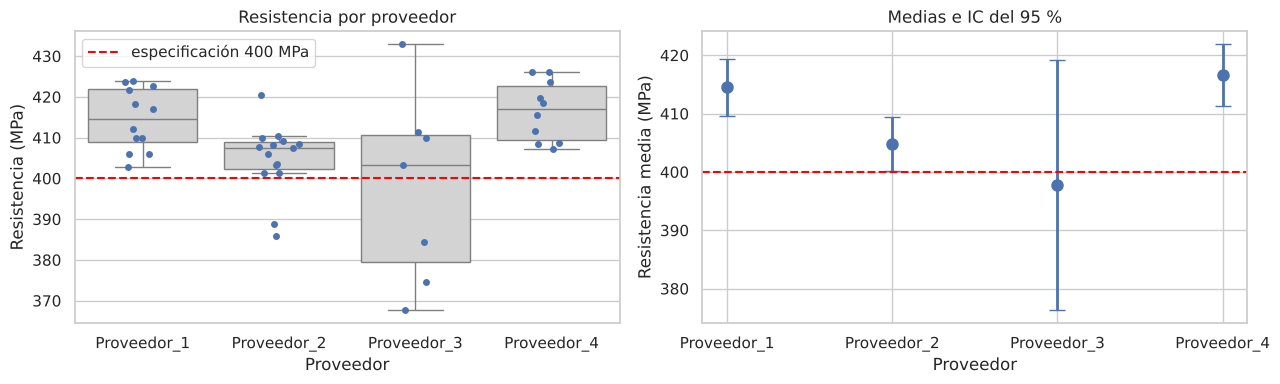

In [55]:
# 1–3. Descripción
print("Parámetros con que se generaron los datos (media, DE, n):", _parametros_taller)
descriptivos_taller = taller.groupby("proveedor").resistencia_MPa.agg(n="count", media="mean", de="std")
display(descriptivos_taller.round(2))
print(f"Cociente DE máx / DE mín = {descriptivos_taller.de.max() / descriptivos_taller.de.min():.1f}; diseño desbalanceado")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=taller, x="proveedor", y="resistencia_MPa", ax=axes[0], color="lightgray", showfliers=False)
sns.stripplot(data=taller, x="proveedor", y="resistencia_MPa", ax=axes[0], jitter=0.15)
axes[0].axhline(400, color="red", ls="--", label="especificación 400 MPa"); axes[0].legend()
axes[0].set(title="Resistencia por proveedor", xlabel="Proveedor", ylabel="Resistencia (MPa)")
grafico_medias_ic(taller, "proveedor", "resistencia_MPa", axes[1], etiqueta_y="Resistencia media (MPa)")
axes[1].axhline(400, color="red", ls="--"); axes[1].set_xlabel("Proveedor")
plt.tight_layout(); plt.show()

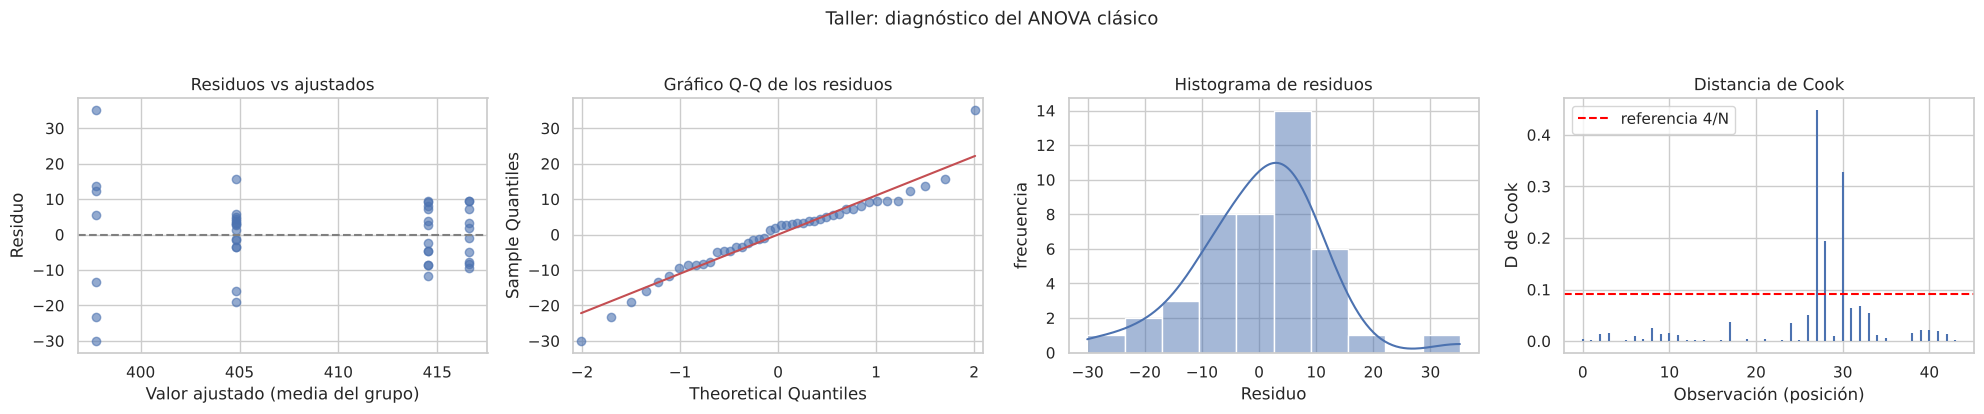

,prueba,estadistico,valor_p
0,Shapiro-Wilk (normalidad de residuos),0.9585,0.1146
1,Levene-mediana (igualdad de varianzas),5.9761,0.0018
2,"Bartlett (igualdad de varianzas, exige normali...",16.8617,0.0008
3,Fligner-Killeen (igualdad de varianzas),9.2117,0.0266


Cociente DE máxima / DE mínima entre grupos: 3.1
Residuos estudentizados con |r| > 3: 2
                df     sum_sq   mean_sq       F  PR(>F)
C(proveedor)   3.0  2091.3687  697.1229  5.2037   0.004
Residual      40.0  5358.7031  133.9676     NaN     NaN

Welch: F(3; 17.5) = 5.73, p = 0.0065


In [56]:
# 4–5. ANOVA clásico, diagnóstico y Welch
modelo_taller = diagnostico_anova(taller, "resistencia_MPa", "proveedor", "Taller: diagnóstico del ANOVA clásico")
tabla_taller = sm.stats.anova_lm(modelo_taller)
welch_taller = anova_oneway(taller.resistencia_MPa, taller.proveedor, use_var="unequal")
print(tabla_taller.round(4))
print(f"\nWelch: F({welch_taller.df_num:.0f}; {welch_taller.df_denom:.1f}) = {welch_taller.statistic:.2f}, p = {welch_taller.pvalue:.4f}")

,comparación,diferencia,gl,IC inferior,IC superior,p ajustado,significativa
0,Proveedor_2 − Proveedor_1,-9.710,24.576,-18.267,-1.153,0.022,True
1,Proveedor_3 − Proveedor_1,-16.760,6.772,-46.927,13.408,0.328,False
2,Proveedor_4 − Proveedor_1,2.083,19.525,-6.929,11.096,0.915,False
3,Proveedor_3 − Proveedor_2,-7.050,6.759,-37.214,23.115,0.861,False
4,Proveedor_4 − Proveedor_2,11.793,21.217,2.888,20.698,0.007,True
5,Proveedor_4 − Proveedor_3,18.843,6.859,-11.324,49.009,0.249,False


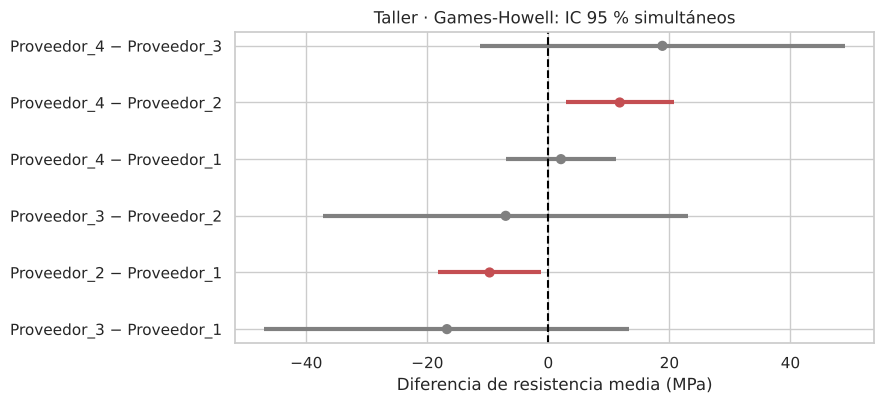

eta²                   0.281
omega²                 0.223
f de Cohen (con η²)    0.625
f de Cohen (con ω²)    0.535
dtype: float64

,IC inf,IC sup,% probetas < 400 MPa
proveedor,,,
Proveedor_1,409.7,419.4,0.0
Proveedor_2,400.1,409.5,13.3
Proveedor_3,376.3,419.2,42.9
Proveedor_4,411.3,421.9,0.0


In [57]:
# 6–7. Games-Howell (varianzas desiguales, n distintos) y tamaños del efecto
gh_taller = games_howell(taller, "resistencia_MPa", "proveedor")
display(gh_taller.round(3))
grafico_comparaciones(gh_taller, "diferencia", "IC inferior", "IC superior", "significativa",
                      "Taller · Games-Howell: IC 95 % simultáneos", "Diferencia de resistencia media (MPa)")
display(pd.Series(tamanos_del_efecto(tabla_taller)).round(3))

# Intervalo de confianza individual para la media de cada proveedor frente a la especificación
ic_medias = taller.groupby("proveedor").resistencia_MPa.apply(
    lambda x: pd.Series(stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x)), index=["IC inf", "IC sup"])).unstack()
ic_medias["% probetas < 400 MPa"] = 100 * taller.groupby("proveedor").resistencia_MPa.apply(lambda x: np.mean(x < 400))
ic_medias.round(1)

**Solución comentada.**

1. Respuesta: resistencia a la tensión (MPa); factor: proveedor (4 niveles); unidad: probeta tomada al azar de los despachos. Es **observacional** (no se asignó nada al azar; se muestrearon despachos existentes), por lo que se habla de diferencias entre proveedores en el período estudiado, sin atribuir causas.
2. $H_0:\mu_1=\mu_2=\mu_3=\mu_4$; $H_1$: al menos una media difiere.
3. – 5. El proveedor 3 tiene la menor cantidad de probetas ($n=7$) y una desviación estándar unas tres veces mayor que la de los demás (23 MPa frente a 7–8 MPa); Levene rechaza la igualdad de varianzas ($p\approx0{,}002$). Los dos residuos estudentizados con $|r|>3$ son probetas de ese proveedor (432,9 y 367,7 MPa), coherentes con su alta variabilidad y no necesariamente errores. Es exactamente el escenario **D** de la simulación de robustez (grupo pequeño con la mayor varianza), en el que la $F$ clásica es liberal. Corresponde **Welch**: $F(3;\,17{,}5)=5{,}73$, $p\approx0{,}007$. Hay evidencia de que la resistencia media difiere entre proveedores.
6. Con varianzas desiguales y $n$ distintos corresponde **Games-Howell**. El proveedor 2 tiene una resistencia media menor que la del proveedor 1 (unos 10 MPa) y que la del proveedor 4 (unos 12 MPa). Un punto didáctico clave: **ninguna comparación con el proveedor 3 es significativa, aunque su media es la más baja**. Con sólo 7 probetas y tanta variabilidad, sus intervalos tienen una amplitud cercana a ±30 MPa. No significa que el proveedor 3 sea comparable a los demás, sino que hay muy poca información sobre él (ausencia de evidencia, no evidencia de ausencia).
7. $\eta^2\approx0{,}28$ y $\omega^2\approx0{,}22$: el proveedor se asocia con alrededor de una quinta parte de la variabilidad de la resistencia.
8. Ejemplo de redacción: *"La resistencia media difiere entre proveedores (ANOVA de Welch, $F(3;\,17{,}5)=5{,}73$, $p=0{,}007$, $\omega^2=0{,}22$); se usó Welch por la mayor variabilidad del proveedor 3. Los proveedores 1 y 4 cumplen con holgura la especificación: sus intervalos de confianza para la media están por encima de 400 MPa y ninguna probeta quedó por debajo. El proveedor 2 tiene una media cercana al límite (405 MPa, IC 95 %: 400–410) y un 13 % de probetas por debajo de 400 MPa. El proveedor 3 es el más riesgoso: media de 398 MPa con gran incertidumbre (IC 95 %: 376–419) y un 43 % de probetas por debajo de la especificación. Se recomienda priorizar a los proveedores 1 y 4 y exigir al proveedor 3 un plan de control de variabilidad. Los resultados describen el trimestre analizado."* Para compras, la **variabilidad** es tan relevante como la media.

## Pistas de los ejercicios por niveles

- **B1.** (a) observacional, unidad: estudiante (o colegio, según la pregunta); (b) experimental, unidad: parcela; (c) observacional, unidad: botella, pero cuidado: las botellas de un mismo turno comparten condiciones.
- **B2.** Pseudorreplicación. El análisis correcto usa las 40 parcelas (por ejemplo, la media de las 5 plantas): $40-4=36$ gl del error.
- **I2.** $SC_E=120$, gl $=3$ y $20$, $CM_{Tr}=28$, $CM_E=6$, $F\approx4{,}67$ frente a $F_{0{,}95;3,20}\approx3{,}10$: se rechaza $H_0$. $\eta^2=84/204\approx0{,}41$; $\omega^2=(84-18)/(204+6)\approx0{,}31$.
- **I3.** Correcta: "si las medias poblacionales fueran iguales (y se cumplieran los supuestos), un $F$ tan grande o mayor ocurriría el 3 % de las veces". Incorrectas: "hay un 3 % de probabilidad de que $H_0$ sea verdadera"; "hay un 97 % de probabilidad de que las medias difieran".
- **A2.** Con $n=5$ y distribución exponencial la tasa se aparta algo del 5 %; con $n=30$ se acerca, porque la distribución de las medias se aproxima a la normal.
- **A3.** Kruskal-Wallis contrasta igualdad de distribuciones; con dispersiones distintas puede rechazar aunque las medianas coincidan.
- **V1.** Un $p$ grande puede deberse a baja potencia; ver la sección 6.3 sobre ausencia de evidencia.
- **V3.** Con referencia *Midsize*, el intercepto es la media de log(precio) de los medianos y cada coeficiente es la diferencia de ese tipo respecto a los medianos. *Large − Small* se obtiene como la diferencia de sus dos coeficientes, y coincide con la diferencia de medias muestrales.